# Preprocessing spleen

# Preprocessing spleen

In [1]:
import os
os.chdir("/sas/sara/scRNAseq/mouse_u1/clean_code/")

from  global_variables_mouse import * 

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scvi/_settings.py:63: UserWarning: Since v1.0.0, scvi-tools no longer uses a random seed by default. Run `scvi.settings.seed = 0` to reproduce results from previous versions.
  self.seed = seed
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scvi/_settings.py:70: UserWarning: Setting `dl_pin_memory_gpu_training` is deprecated in v1.0 and will be removed in v1.1. Please pass in `pin_memory` to the data loaders instead.
  self.dl_pin_memory_gpu_training = (
2025-11-27 12:11:10.030718: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-11-27 12:11:10.030763: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-11-27 12:11:10.030810:

In [2]:
%matplotlib inline

plt.rcParams['figure.dpi'] = 100

sns.set_theme(context='notebook', style="white", palette=spectrum)

In [3]:
metadata = pd.read_csv("/sas/sara/scRNAseq/pendas/metadata.txt",sep="\t")
metadata.head(20)

,Path,Sample_ID,Group,Path cellbender
0,/data/NGS/scRNAseq/pendas/FASTQ/SI-TT-A1/SI-TT...,SI-TT-A1,SIX6_D_Cterm,/data/NGS/scRNAseq/pendas/FASTQ/SI-TT-A1/SI-TT...
1,/data/NGS/scRNAseq/pendas/FASTQ/SI-TT-B1/SI-TT...,SI-TT-B1,WT2,/data/NGS/scRNAseq/pendas/FASTQ/SI-TT-B1/SI-TT...
2,/data/NGS/scRNAseq/pendas/FASTQ/SI-TT-C1/SI-TT...,SI-TT-C1,WT1,/data/NGS/scRNAseq/pendas/FASTQ/SI-TT-C1/SI-TT...
3,/data/NGS/scRNAseq/pendas/FASTQ/SI-TT-D1/SI-TT...,SI-TT-D1,H2AX_KI,/data/NGS/scRNAseq/pendas/FASTQ/SI-TT-D1/SI-TT...
4,/data/NGS/scRNAseq/pendas/FASTQ/SI-TT-H12/SI-T...,SI-TT-H12,RNF212_KO,/data/NGS/scRNAseq/pendas/FASTQ/SI-TT-H12/SI-T...


In [4]:
adatas_dict_raw={}   ## Create dict
for index,row in metadata.iterrows():
    name=row['Sample_ID']
    adata = sc.read_10x_h5(row['Path']+"/raw_feature_bc_matrix.h5")
    adatas_dict_raw[name]=adata
    adatas_dict_raw[name].obs["Sample"]=row["Sample_ID"]
    adatas_dict_raw[name].obs["Group"]=row["Group"]

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/anndata/_core/anndata.py:1899: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/anndata/_core/anndata.py:1899: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/anndata/_core/anndata.py:1899: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/anndata/_core/anndata.py:1899: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages

In [5]:
adatas_dict={}   ## Create dict
for index,row in metadata.iterrows():
    name=row['Sample_ID']
    adata = sc.read_10x_h5(row['Path']+"/cellbender_2_z100_filtered.h5")
    adatas_dict[name]=adata
    adatas_dict[name].obs["Sample"]=row["Sample_ID"]
    adatas_dict[name].obs["Group"]=row["Group"]


/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/anndata/_core/anndata.py:1899: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/anndata/_core/anndata.py:1899: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/anndata/_core/anndata.py:1899: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/anndata/_core/anndata.py:1899: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages

In [6]:
for key in adatas_dict:
     adatas_dict[key].var_names_make_unique()
    
for key in adatas_dict_raw:
     adatas_dict_raw[key].var_names_make_unique()

In [7]:
adatas_dict

{'SI-TT-A1': AnnData object with n_obs × n_vars = 11219 × 32285
     obs: 'Sample', 'Group'
     var: 'gene_ids', 'feature_types', 'genome',
 'SI-TT-B1': AnnData object with n_obs × n_vars = 9568 × 32285
     obs: 'Sample', 'Group'
     var: 'gene_ids', 'feature_types', 'genome',
 'SI-TT-C1': AnnData object with n_obs × n_vars = 18669 × 32285
     obs: 'Sample', 'Group'
     var: 'gene_ids', 'feature_types', 'genome',
 'SI-TT-D1': AnnData object with n_obs × n_vars = 14507 × 32285
     obs: 'Sample', 'Group'
     var: 'gene_ids', 'feature_types', 'genome',
 'SI-TT-H12': AnnData object with n_obs × n_vars = 7029 × 32285
     obs: 'Sample', 'Group'
     var: 'gene_ids', 'feature_types', 'genome'}

In [8]:
for key in adatas_dict:
      sc.pp.filter_cells(adatas_dict[key], min_genes=100)
      sc.pp.filter_genes(adatas_dict[key], min_cells=5)
      sc.pp.filter_cells(adatas_dict[key], max_counts=100000)
      sc.pp.filter_cells(adatas_dict[key], min_counts=300)


In [9]:
adatas_dict_raw

{'SI-TT-A1': AnnData object with n_obs × n_vars = 1279855 × 32285
     obs: 'Sample', 'Group'
     var: 'gene_ids', 'feature_types', 'genome',
 'SI-TT-B1': AnnData object with n_obs × n_vars = 1993688 × 32285
     obs: 'Sample', 'Group'
     var: 'gene_ids', 'feature_types', 'genome',
 'SI-TT-C1': AnnData object with n_obs × n_vars = 1793253 × 32285
     obs: 'Sample', 'Group'
     var: 'gene_ids', 'feature_types', 'genome',
 'SI-TT-D1': AnnData object with n_obs × n_vars = 1191947 × 32285
     obs: 'Sample', 'Group'
     var: 'gene_ids', 'feature_types', 'genome',
 'SI-TT-H12': AnnData object with n_obs × n_vars = 1620287 × 32285
     obs: 'Sample', 'Group'
     var: 'gene_ids', 'feature_types', 'genome'}

In [10]:
adatas_dict

{'SI-TT-A1': AnnData object with n_obs × n_vars = 10371 × 19488
     obs: 'Sample', 'Group', 'n_genes', 'n_counts'
     var: 'gene_ids', 'feature_types', 'genome', 'n_cells',
 'SI-TT-B1': AnnData object with n_obs × n_vars = 7243 × 21377
     obs: 'Sample', 'Group', 'n_genes', 'n_counts'
     var: 'gene_ids', 'feature_types', 'genome', 'n_cells',
 'SI-TT-C1': AnnData object with n_obs × n_vars = 5569 × 21056
     obs: 'Sample', 'Group', 'n_genes', 'n_counts'
     var: 'gene_ids', 'feature_types', 'genome', 'n_cells',
 'SI-TT-D1': AnnData object with n_obs × n_vars = 12252 × 19276
     obs: 'Sample', 'Group', 'n_genes', 'n_counts'
     var: 'gene_ids', 'feature_types', 'genome', 'n_cells',
 'SI-TT-H12': AnnData object with n_obs × n_vars = 6175 × 19733
     obs: 'Sample', 'Group', 'n_genes', 'n_counts'
     var: 'gene_ids', 'feature_types', 'genome', 'n_cells'}

In [11]:
for key in adatas_dict_raw:
     adatas_dict_raw[key] = adatas_dict_raw[key][adatas_dict_raw[key].obs.index.isin(adatas_dict[key].obs.index)]

In [12]:
for key in adatas_dict_raw:
    shared_genes = adatas_dict_raw[key].var_names.intersection(adatas_dict[key].var_names)
    adatas_dict_raw[key] = adatas_dict_raw[key][:, shared_genes]


In [13]:
adatas_dict_raw

{'SI-TT-A1': View of AnnData object with n_obs × n_vars = 10371 × 19488
     obs: 'Sample', 'Group'
     var: 'gene_ids', 'feature_types', 'genome',
 'SI-TT-B1': View of AnnData object with n_obs × n_vars = 7243 × 21377
     obs: 'Sample', 'Group'
     var: 'gene_ids', 'feature_types', 'genome',
 'SI-TT-C1': View of AnnData object with n_obs × n_vars = 5569 × 21056
     obs: 'Sample', 'Group'
     var: 'gene_ids', 'feature_types', 'genome',
 'SI-TT-D1': View of AnnData object with n_obs × n_vars = 12252 × 19276
     obs: 'Sample', 'Group'
     var: 'gene_ids', 'feature_types', 'genome',
 'SI-TT-H12': View of AnnData object with n_obs × n_vars = 6175 × 19733
     obs: 'Sample', 'Group'
     var: 'gene_ids', 'feature_types', 'genome'}

### Calculate QC

In [14]:
for key in adatas_dict_raw:
    adatas_dict_raw[key].var['mt'] = adatas_dict_raw[key].var_names.str.startswith('mt-')  # annotate the group of mitochondrial genes as 'mt'
    adatas_dict_raw[key].var['rb'] = adatas_dict_raw[key].var_names.str.startswith(('Rpl','Rps'))  # annotate the group of ribosomal proteins as 'rb'
    sc.pp.calculate_qc_metrics(adatas_dict_raw[key], qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)
    sc.pp.calculate_qc_metrics(adatas_dict_raw[key], qc_vars=['rb'], percent_top=None, log1p=False, inplace=True)
    sc.pp.calculate_qc_metrics(adatas_dict_raw[key], qc_vars=["mt", "rb"], inplace=True, percent_top=[20], log1p=True
)

/tmp/ipykernel_247376/2435598351.py:2: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adatas_dict_raw[key].var['mt'] = adatas_dict_raw[key].var_names.str.startswith('mt-')  # annotate the group of mitochondrial genes as 'mt'
/tmp/ipykernel_247376/2435598351.py:2: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adatas_dict_raw[key].var['mt'] = adatas_dict_raw[key].var_names.str.startswith('mt-')  # annotate the group of mitochondrial genes as 'mt'
/tmp/ipykernel_247376/2435598351.py:2: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adatas_dict_raw[key].var['mt'] = adatas_dict_raw[key].var_names.str.startswith('mt-')  # annotate the group of mitochondrial genes as 'mt'
/tmp/ipykernel_247376/2435598351.py:2: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adatas_dict_raw

In [15]:
for key in adatas_dict:
    adatas_dict[key].var['mt'] = adatas_dict[key].var_names.str.startswith('mt-')  # annotate the group of mitochondrial genes as 'mt'
    adatas_dict[key].var['rb'] = adatas_dict[key].var_names.str.startswith(('Rpl','Rps'))  # annotate the group of ribosomal proteins as 'rb'
    sc.pp.calculate_qc_metrics(adatas_dict[key], qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)
    sc.pp.calculate_qc_metrics(adatas_dict[key], qc_vars=['rb'], percent_top=None, log1p=False, inplace=True)
    sc.pp.calculate_qc_metrics(adatas_dict[key], qc_vars=["mt", "rb"], inplace=True, percent_top=[20], log1p=True
)

In [16]:
adatas_dict_raw["SI-TT-A1"]

AnnData object with n_obs × n_vars = 10371 × 19488
    obs: 'Sample', 'Group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_mean_counts', 'log1p_total_counts'

/tmp/ipykernel_247376/1227897041.py:14: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0,100000)


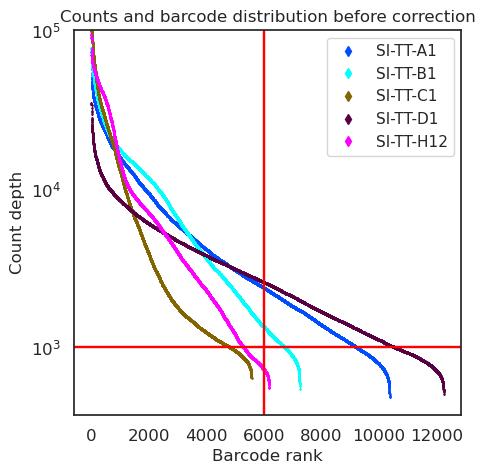

In [17]:
x=0
for key in adatas_dict_raw:
    x+=1
    plt.rcParams['figure.figsize']=(5,5)
    count_data = adatas_dict_raw[key].obs['total_counts'].copy()
    count_data.sort_values(inplace=True, ascending=False)
    order =  range(1, len(count_data)+1)
    ax = plt.semilogy(order, count_data, 'd',label=key,color=categorical_palette[x],markersize=1)  #log scaling on the y axis
    plt.gca().axhline(1000, 0,1, color='red')
    plt.gca().axvline(6000, 0, 1, color='red')
    plt.xlabel("Barcode rank", fontsize=12)
    plt.ylabel("Count depth", fontsize=12)
    plt.tick_params(labelsize=12)
    plt.ylim(0,100000)

    plt.title("Counts and barcode distribution before correction")
    plt.legend(loc="upper right", markerscale=5)


/tmp/ipykernel_247376/3823573669.py:15: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0,100000)


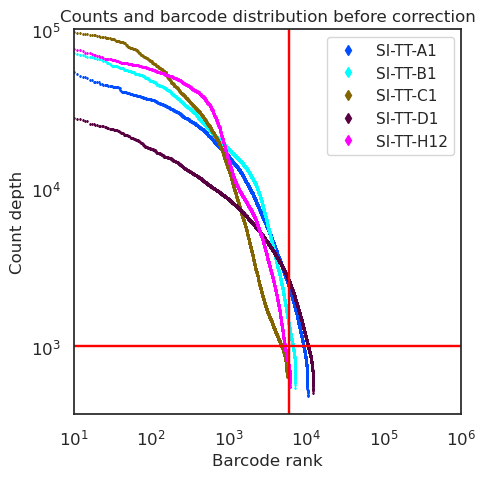

In [18]:
x=0
for key in adatas_dict_raw:
    x+=1
    plt.rcParams['figure.figsize']=(5,5)
    count_data = adatas_dict_raw[key].obs['total_counts'].copy()
    count_data.sort_values(inplace=True, ascending=False)
    order =  range(1, len(count_data)+1)
    ax = plt.semilogy(order, count_data, 'd',label=key,color=categorical_palette[x],markersize=1)  #log scaling on the y axis
    plt.gca().axhline(1000, 0,1, color='red')
    plt.gca().axvline(6000, 0, 1, color='red')
    plt.xlabel("Barcode rank", fontsize=12)
    plt.ylabel("Count depth", fontsize=12)
    plt.tick_params(labelsize=12)
    plt.xlim(10,1000000)
    plt.ylim(0,100000)
    plt.xscale('log')

    plt.title("Counts and barcode distribution before correction")
    plt.legend(loc="upper right", markerscale=5)


/tmp/ipykernel_247376/2121631176.py:15: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0,100000)


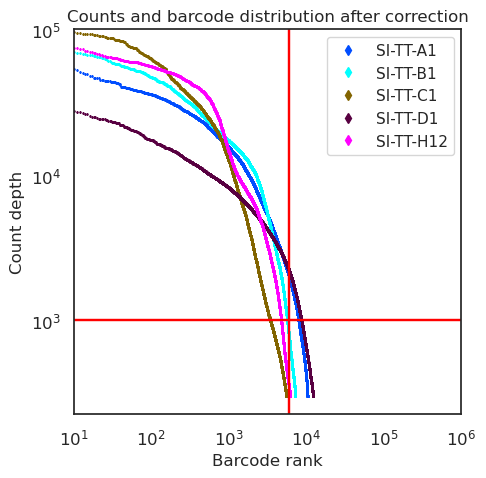

In [19]:
x=0
for key in adatas_dict:
    x+=1
    plt.rcParams['figure.figsize']=(5,5)
    count_data = adatas_dict[key].obs['total_counts'].copy()
    count_data.sort_values(inplace=True, ascending=False)
    order =  range(1, len(count_data)+1)
    ax = plt.semilogy(order, count_data, 'd',label=key,color=categorical_palette[x],markersize=1)  #log scaling on the y axis
    plt.gca().axhline(1000, 0,1, color='red')
    plt.gca().axvline(6000, 0, 1, color='red')
    plt.xlabel("Barcode rank", fontsize=12)
    plt.ylabel("Count depth", fontsize=12)
    plt.tick_params(labelsize=12)
    plt.xlim(10,1000000)
    plt.ylim(0,100000)
    plt.xscale('log')

    plt.title("Counts and barcode distribution after correction")
    plt.legend(loc="upper right", markerscale=5)


In [20]:
adatas_dict

{'SI-TT-A1': AnnData object with n_obs × n_vars = 10371 × 19488
     obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb'
     var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_mean_counts', 'log1p_total_counts',
 'SI-TT-B1': AnnData object with n_obs × n_vars = 7243 × 21377
     obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb'
     var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rb', 'n_cells_by_counts', 'mean_coun

In [21]:

for key in adatas_dict:
    adatas_dict[key].var['mt'] = adatas_dict[key].var_names.str.startswith('mt-')  # annotate the group of mitochondrial genes as 'mt'
    adatas_dict[key].var['rb'] = adatas_dict[key].var_names.str.startswith(('Rpl','Rps'))  # annotate the group of ribosomal proteins as 'rb'
    sc.pp.calculate_qc_metrics(adatas_dict[key], qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)
    sc.pp.calculate_qc_metrics(adatas_dict[key], qc_vars=['rb'], percent_top=None, log1p=False, inplace=True)
    sc.pp.calculate_qc_metrics(adatas_dict[key], qc_vars=["mt", "rb"], inplace=True, percent_top=[20], log1p=True
)

In [22]:


for key in adatas_dict_raw:
    adatas_dict_raw[key].var['mt'] = adatas_dict_raw[key].var_names.str.startswith('mt-')  # annotate the group of mitochondrial genes as 'mt'
    adatas_dict_raw[key].var['rb'] = adatas_dict_raw[key].var_names.str.startswith(('Rpl','Rps'))  # annotate the group of ribosomal proteins as 'rb'
    sc.pp.calculate_qc_metrics(adatas_dict_raw[key], qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)
    sc.pp.calculate_qc_metrics(adatas_dict_raw[key], qc_vars=['rb'], percent_top=None, log1p=False, inplace=True)
    sc.pp.calculate_qc_metrics(adatas_dict_raw[key], qc_vars=["mt", "rb"], inplace=True, percent_top=[20], log1p=True
)

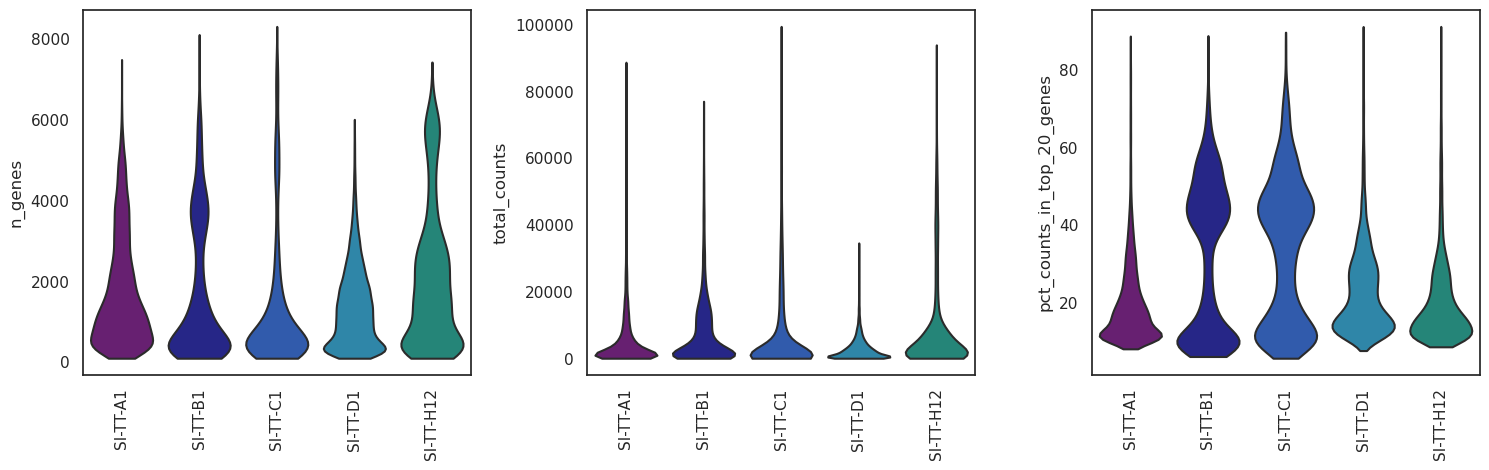

In [23]:
### Sólo para los gráficos
adatas=[]
for x in list(adatas_dict.keys())[1:]:
    adatas.append(adatas_dict[x])
    
merged=adatas_dict[list(adatas_dict.keys())[0]].concatenate(adatas)


sc.pl.violin(
        merged,
        ['n_genes', 'total_counts', "pct_counts_in_top_20_genes"],
        jitter=0.4,
        groupby='Sample',
        rotation=90,
        stripplot=False,hspace=0.7
    )
    




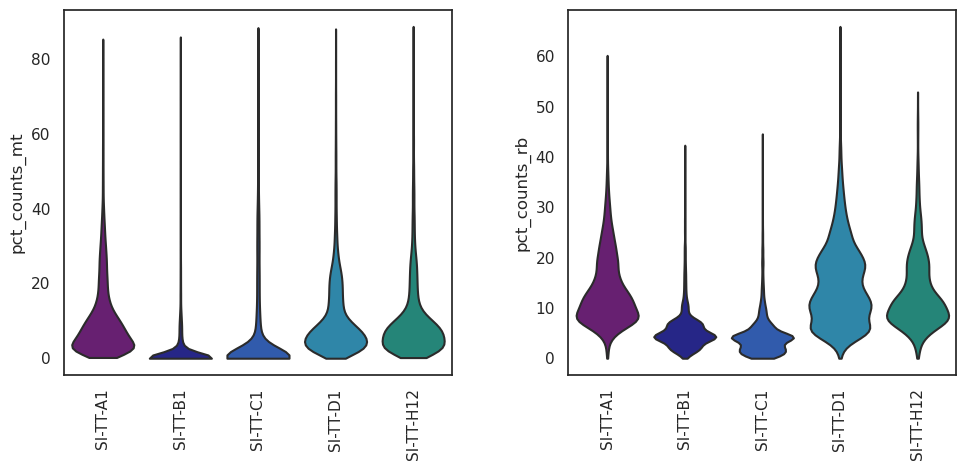

In [24]:
sc.pl.violin(
        merged,
        ['pct_counts_mt','pct_counts_rb'],
        jitter=0.4,
        groupby='Sample',
        rotation=90,
        stripplot=False
    )


Text(0.5, 1.0, 'number of counts displot')

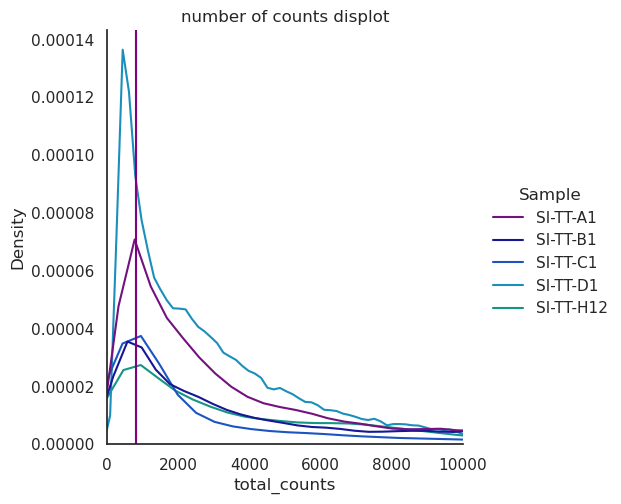

In [25]:
ax = sns.displot(merged.obs, x="total_counts", kind="kde",hue="Sample",bw_adjust=.25)
plt.axvline(800, 0,1,color="purple")
plt.xlim(0,10000)
plt.title("number of counts displot")

(0.0, 4000.0)

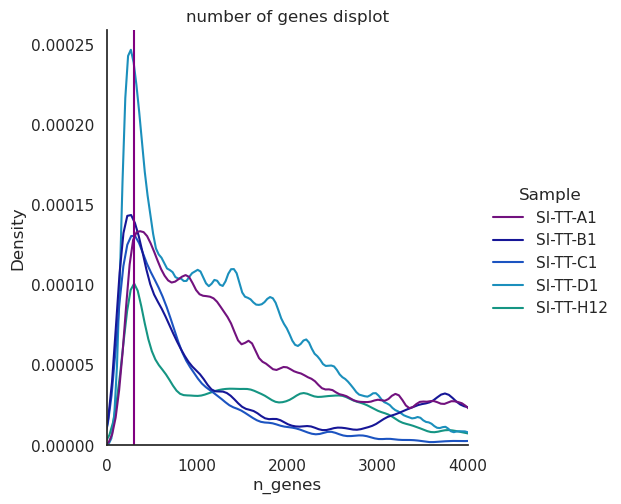

In [26]:
ax = sns.displot(merged.obs, x="n_genes", kind="kde",hue="Sample",bw_adjust=.25)
plt.axvline(300, 0,1,color="purple")
plt.title("number of genes displot")
plt.xlim(0,4000)

In [27]:
adatas_dict

{'SI-TT-A1': AnnData object with n_obs × n_vars = 10371 × 19488
     obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb'
     var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_mean_counts', 'log1p_total_counts',
 'SI-TT-B1': AnnData object with n_obs × n_vars = 7243 × 21377
     obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb'
     var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rb', 'n_cells_by_counts', 'mean_coun

(-1.0, 30.0)

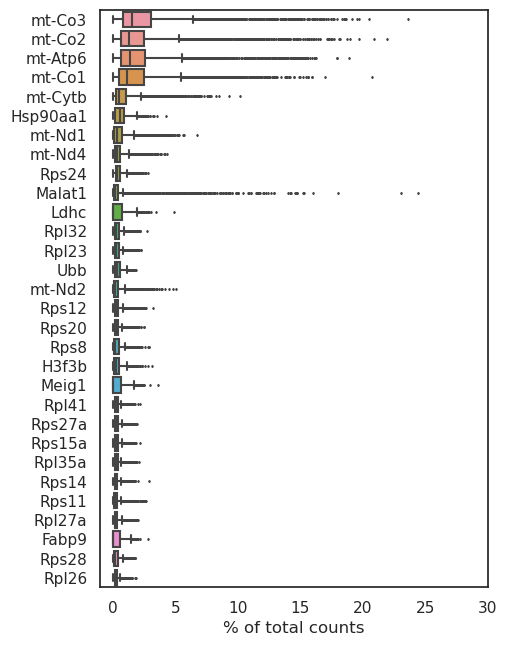

In [28]:
sc.pl.highest_expr_genes(adatas_dict["SI-TT-A1"], show=False)
plt.xlim(-1, 30)

(-1.0, 30.0)

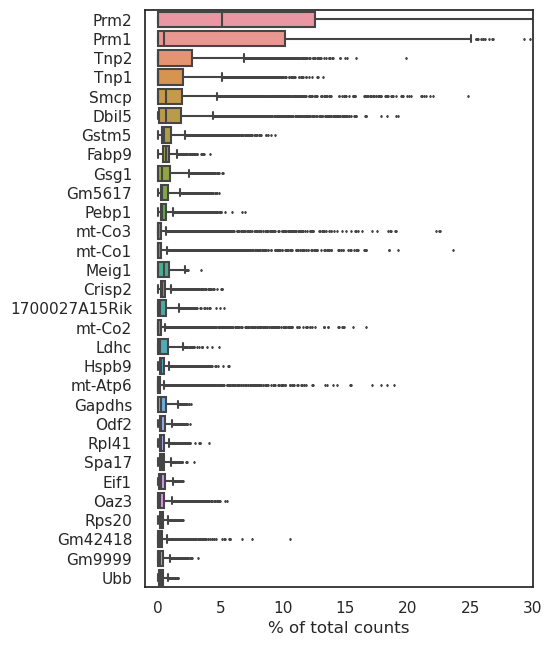

In [29]:
sc.pl.highest_expr_genes(adatas_dict["SI-TT-B1"],show=False)
plt.xlim(-1, 30)

## Without correction

In [30]:
adatas_dict_raw

{'SI-TT-A1': AnnData object with n_obs × n_vars = 10371 × 19488
     obs: 'Sample', 'Group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb'
     var: 'gene_ids', 'feature_types', 'genome', 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_mean_counts', 'log1p_total_counts',
 'SI-TT-B1': AnnData object with n_obs × n_vars = 7243 × 21377
     obs: 'Sample', 'Group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb'
     var: 'gene_ids', 'feature_types', 'genome', 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_mean_counts', '

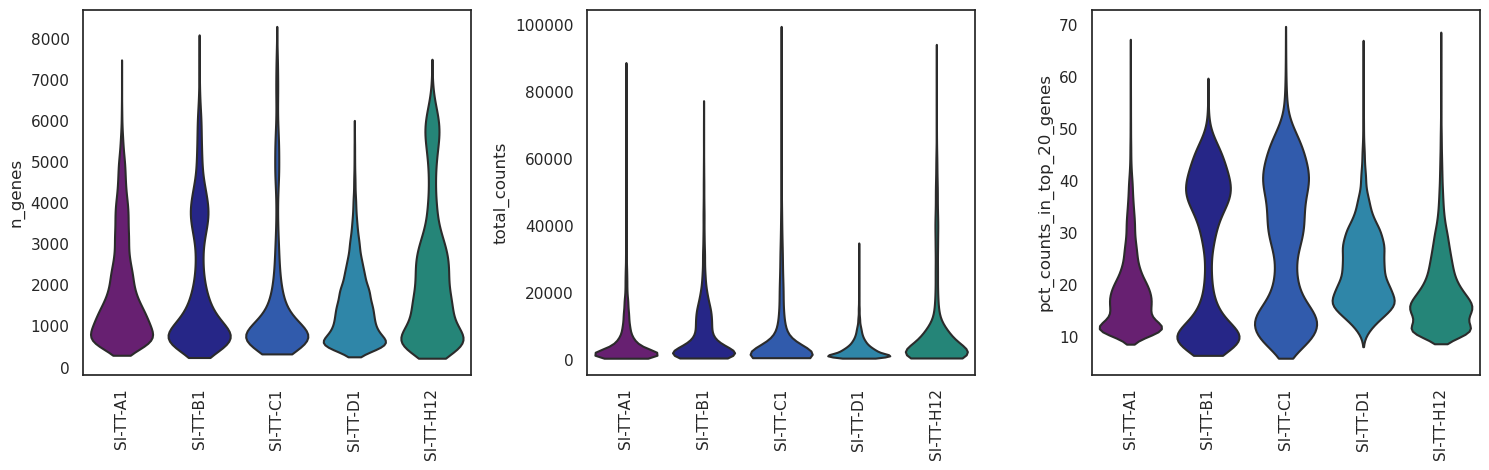

In [31]:
for key in adatas_dict_raw:
      sc.pp.filter_cells(adatas_dict_raw[key], min_genes=10)
      sc.pp.filter_genes(adatas_dict_raw[key], min_cells=1)

### Sólo para los gráficos
adatas=[]
for x in list(adatas_dict_raw.keys())[1:]:
    adatas.append(adatas_dict_raw[x])
    
merged_raw=adatas_dict_raw[list(adatas_dict_raw.keys())[0]].concatenate(adatas)


sc.pl.violin(
        merged_raw,
        ['n_genes', 'total_counts', "pct_counts_in_top_20_genes"],
        jitter=0.4,
        groupby='Sample',
        rotation=90,
        stripplot=False
    )


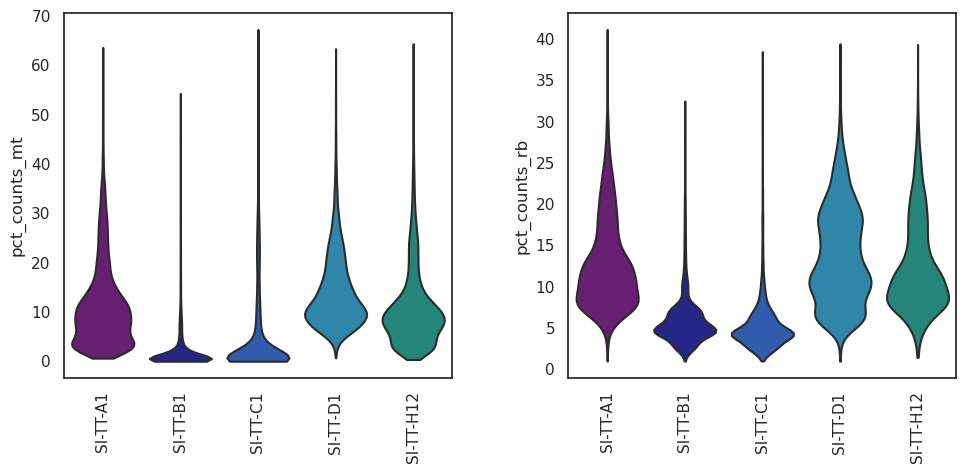

In [32]:
sc.pl.violin(
        merged_raw,
         ['pct_counts_mt','pct_counts_rb'],
        jitter=0.4,
        groupby='Sample',
        rotation=90,
        stripplot=False
    )
    

Text(0.5, 1.0, 'number of counts displot')

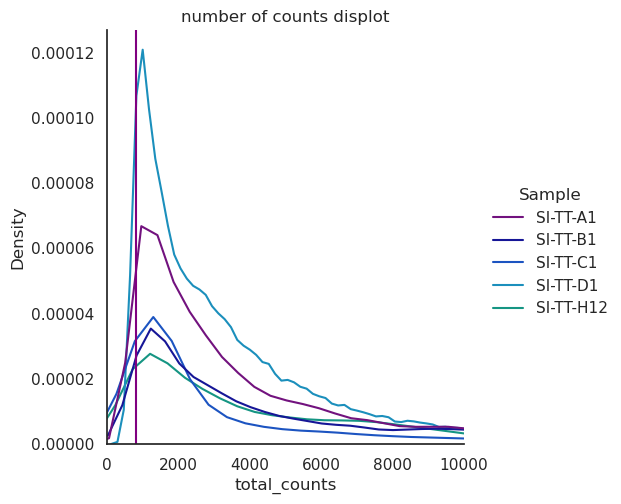

In [33]:
ax = sns.displot(merged_raw.obs, x="total_counts", kind="kde",hue="Sample",bw_adjust=.25)
plt.axvline(800, 0,1,color="purple")
plt.xlim(0,10000)
plt.title("number of counts displot")

(0.0, 4000.0)

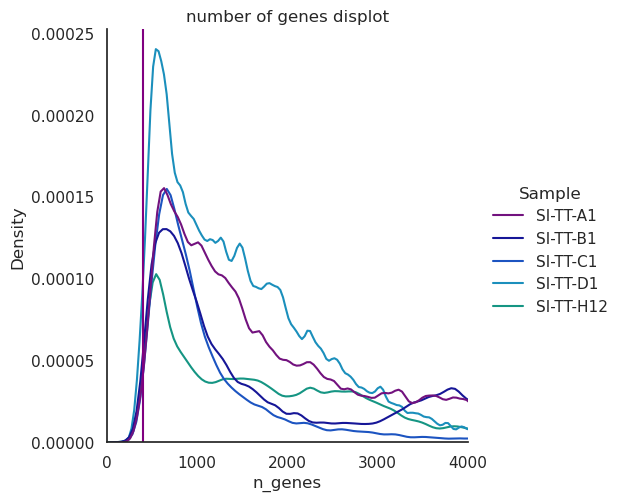

In [34]:
ax = sns.displot(merged_raw.obs, x="n_genes", kind="kde",hue="Sample",bw_adjust=.25)
plt.axvline(400, 0,1,color="purple")
plt.title("number of genes displot")
plt.xlim(0,4000)

(-1.0, 30.0)

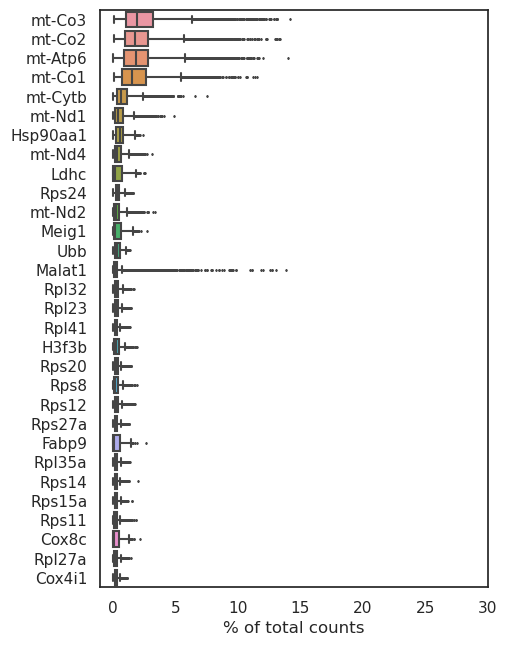

In [35]:
sc.pl.highest_expr_genes(adatas_dict_raw["SI-TT-A1"],show=False)
plt.xlim(-1, 30)

(-1.0, 30.0)

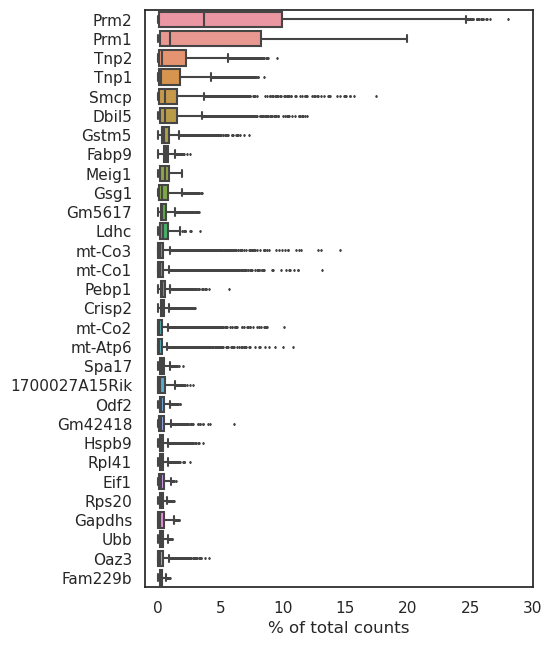

In [36]:
sc.pl.highest_expr_genes(adatas_dict_raw["SI-TT-B1"],show=False)
plt.xlim(-1, 30)

In [37]:
### Analysis subpopulations
temp = pd.DataFrame(merged.obs["Sample"])
temp["barcodes"] = list(merged.obs.index)
count=temp.groupby(["Sample"]).count()
count["Sample"]= count.index
count

,barcodes,Sample
Sample,,
SI-TT-A1,10371,SI-TT-A1
SI-TT-B1,7243,SI-TT-B1
SI-TT-C1,5569,SI-TT-C1
SI-TT-D1,12252,SI-TT-D1
SI-TT-H12,6175,SI-TT-H12


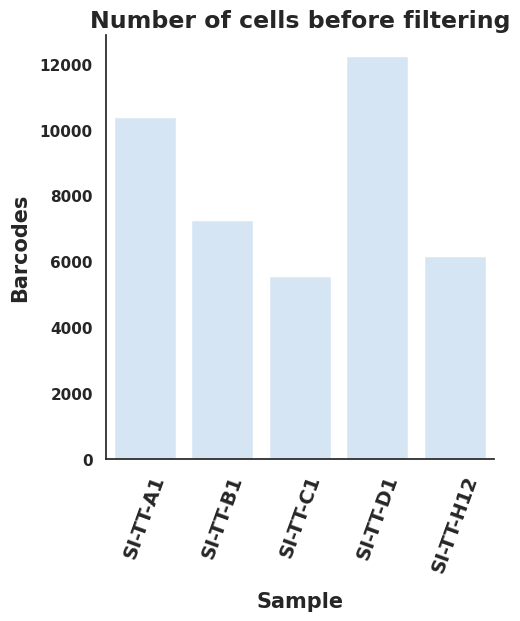

In [38]:
plt.rcdefaults()
sns.set_theme(style="white")
plt.rcParams.update({"axes.labelpad":40,"axes.labelweight":"bold","axes.titleweight":"bold",'font.size': 13, "font.weight":"bold"})

plt.figure(figsize=[5, 5.5])
sns.barplot(data=count, x="Sample", y="barcodes",color="#D1E5F8")
plt.xticks(rotation=70,size=14)
plt.ylabel("Barcodes",labelpad=7,size=15)
plt.xlabel("Sample",labelpad=12,size=15)
plt.title("Number of cells before filtering",weight="bold",size=17)
sns.despine()

plt.savefig("/sas/sara/scRNAseq/pendas/figures/Barplor_barcodes_per_sample.png", format="png", bbox_inches="tight",dpi=600)


Text(0.5, 1.0, 'number of counts displot before filtering')

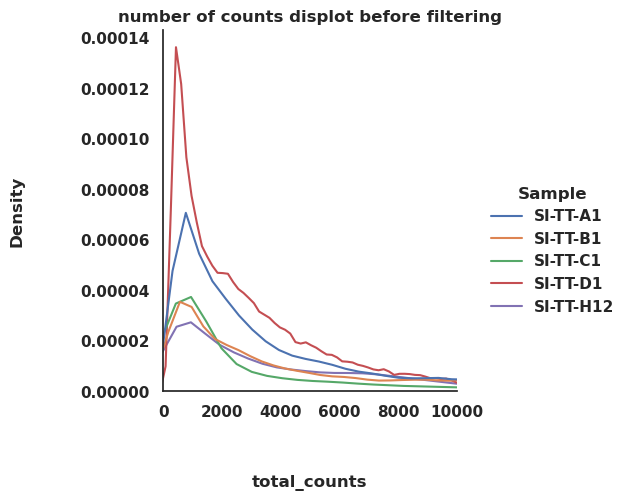

In [39]:
ax = sns.displot(merged.obs, x="total_counts", kind="kde",hue="Sample",bw_adjust=.25)
#plt.axvline(1300, 0,1,color="purple")
plt.xlim(0,10000)
plt.title("number of counts displot before filtering")

(0.0, 4000.0)

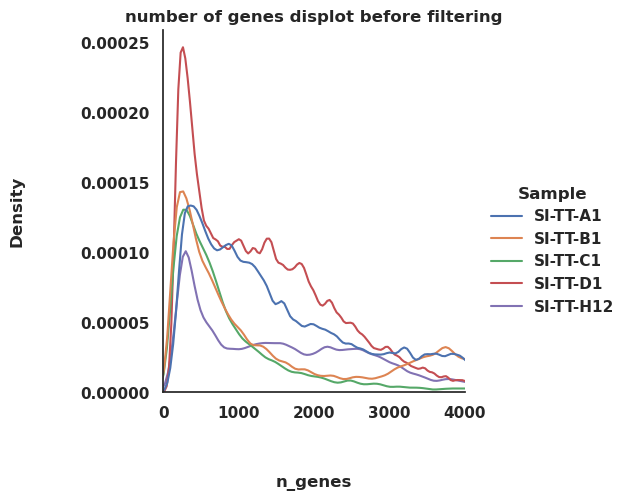

In [40]:
ax = sns.displot(merged.obs, x="n_genes", kind="kde",hue="Sample",bw_adjust=.25)
#plt.axvline(600, 0,1,color="purple")
plt.title("number of genes displot before filtering")
plt.xlim(0,4000)

Text(0.5, 1.0, 'Highest expressed genes')

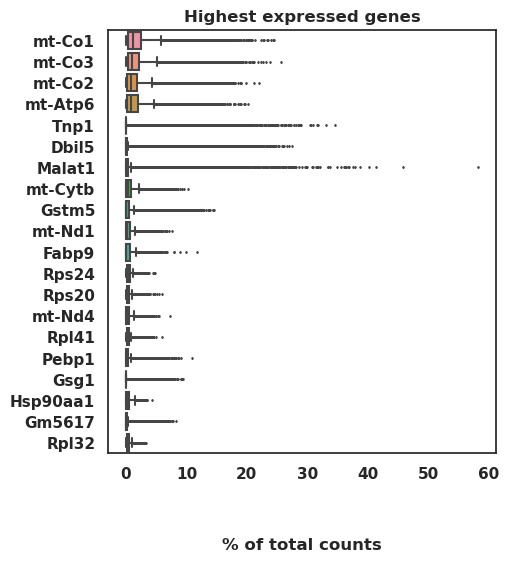

In [41]:
ax = sc.pl.highest_expr_genes(merged, n_top=20,show=False)
plt.title("Highest expressed genes")

In [42]:
adatas_dict

{'SI-TT-A1': AnnData object with n_obs × n_vars = 10371 × 19488
     obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb'
     var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_mean_counts', 'log1p_total_counts',
 'SI-TT-B1': AnnData object with n_obs × n_vars = 7243 × 21377
     obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb'
     var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rb', 'n_cells_by_counts', 'mean_coun

In [43]:
for key in adatas_dict:
    adatas_dict[key] = adatas_dict[key][adatas_dict[key].obs['pct_counts_in_top_20_genes'] < 40].copy()
    adatas_dict[key] = adatas_dict[key][adatas_dict[key].obs['pct_counts_mt'] < 30].copy()



## Filtering MAD

In [44]:
adatas=[]
for x in list(adatas_dict.keys())[1:]:
    adatas.append(adatas_dict[x])
    
merged=adatas_dict[list(adatas_dict.keys())[0]].concatenate(adatas)

In [45]:
### Analysis subpopulations
temp = pd.DataFrame(merged.obs["Sample"])
temp["barcodes"] = list(merged.obs.index)
count=temp.groupby(["Sample"]).count()
count["Sample"]= count.index
count

,barcodes,Sample
Sample,,
SI-TT-A1,9641,SI-TT-A1
SI-TT-B1,3819,SI-TT-B1
SI-TT-C1,2974,SI-TT-C1
SI-TT-D1,11279,SI-TT-D1
SI-TT-H12,5773,SI-TT-H12


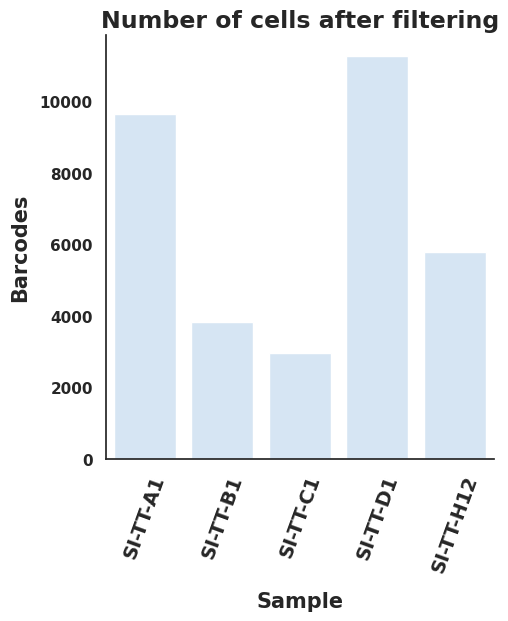

In [46]:
plt.rcdefaults()
sns.set_theme(style="white")
plt.rcParams.update({"axes.labelpad":40,"axes.labelweight":"bold","axes.titleweight":"bold",'font.size': 13, "font.weight":"bold"})

plt.figure(figsize=[5, 5.5])
sns.barplot(data=count, x="Sample", y="barcodes",color="#D1E5F8")
plt.xticks(rotation=70,size=14)
plt.ylabel("Barcodes",labelpad=7,size=15)
plt.xlabel("Sample",labelpad=12,size=15)
plt.title("Number of cells after filtering",weight="bold",size=17)
sns.despine()

plt.savefig("/sas/sara/scRNAseq/pendas/figures/Barplor_barcodes_per_sample_AFTER.png", format="png", bbox_inches="tight",dpi=600)


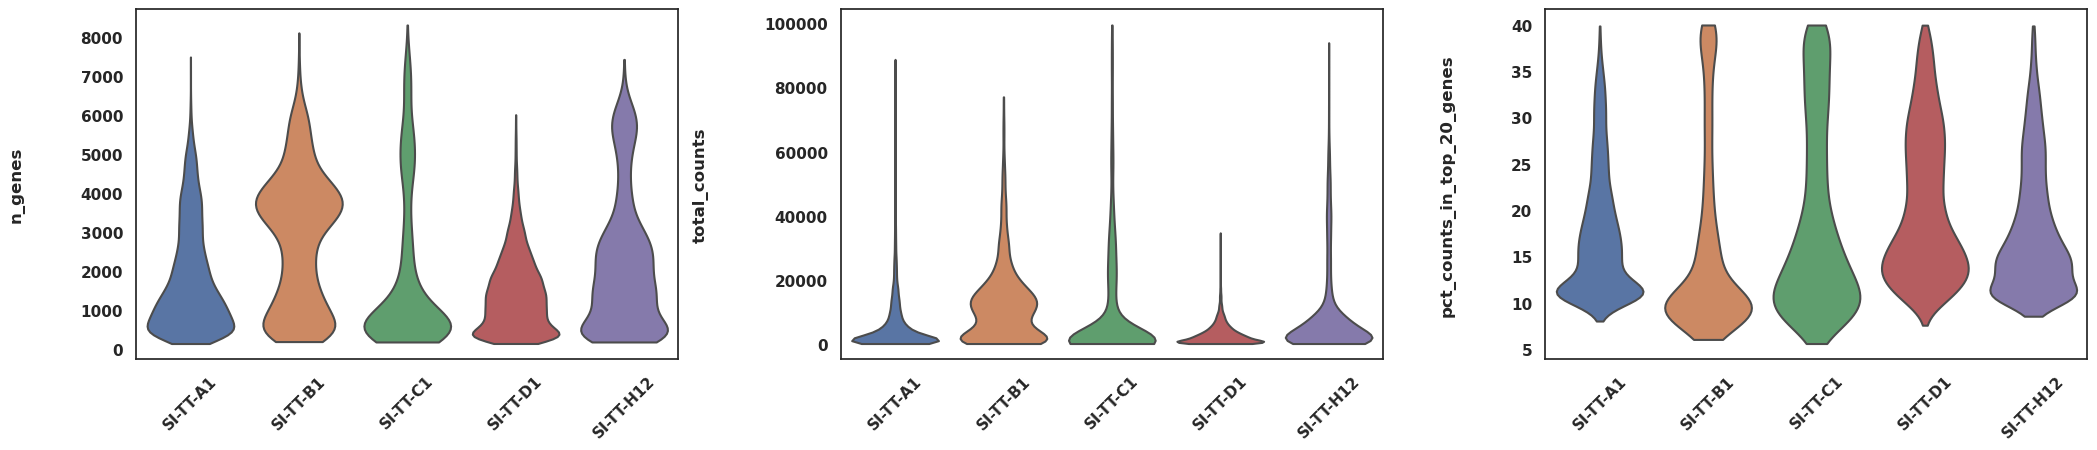

In [47]:
adatas=[]
for x in list(adatas_dict.keys())[1:]:
    adatas.append(adatas_dict[x])
    
merged=adatas_dict[list(adatas_dict.keys())[0]].concatenate(adatas)
sc.pl.violin(merged, ['n_genes', 'total_counts','pct_counts_in_top_20_genes'],
             jitter=0.4, groupby = 'Sample', rotation = 45,stripplot=False)

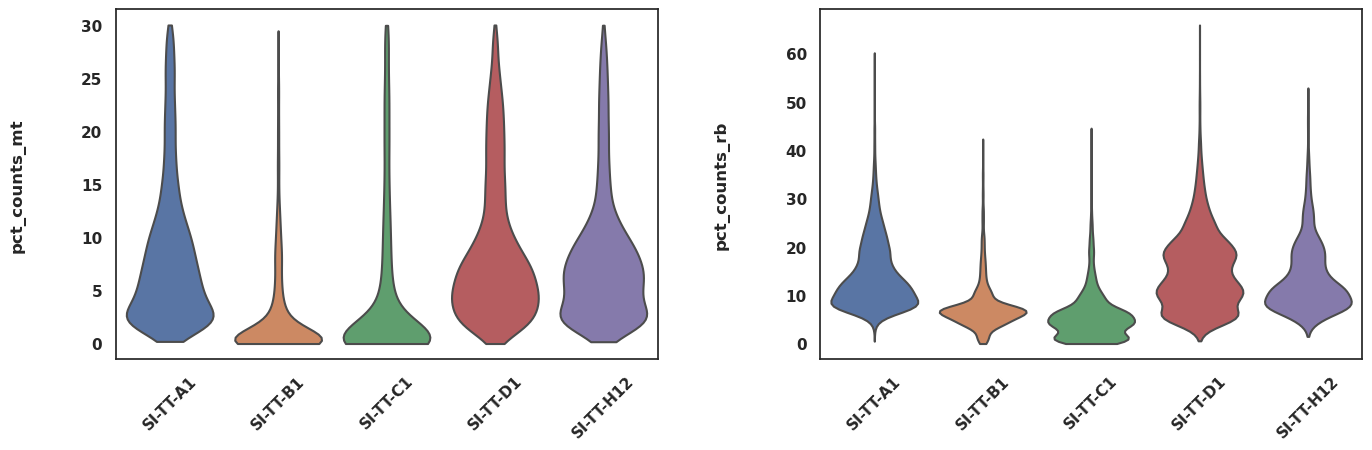

In [48]:
sc.pl.violin(merged, ['pct_counts_mt','pct_counts_rb'],
             jitter=0.4, groupby = 'Sample', rotation = 45,stripplot=False)

#### Doublet detection DoubletDetection

In [49]:
for key in adatas_dict:
    clf = doubletdetection.BoostClassifier(
    n_iters=10,
    clustering_algorithm="louvain",
    standard_scaling=True,
    pseudocount=0.1,
    n_jobs=-1,
)
    doublets = clf.fit(adatas_dict[key].X).predict(p_thresh=1e-16, voter_thresh=0.5)
    doublet_score = clf.doublet_score()
    adatas_dict[key].obs["doublet"] = doublets
    adatas_dict[key].obs["doublet_score"] = doublet_score  

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

In [50]:
remap = {
    0.0:"Singlet",
    1.0:"Doublet"
}

for key in adatas_dict:

    adatas_dict[key].obs["doublet_doubletdetection"]= adatas_dict[key].obs["doublet"]
    adatas_dict[key].obs["doublet_doubletdetection"] = adatas_dict[key].obs["doublet_doubletdetection"].map(remap).astype('category')

In [51]:
adatas_dict

{'SI-TT-A1': AnnData object with n_obs × n_vars = 9641 × 19488
     obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection'
     var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_mean_counts', 'log1p_total_counts',
 'SI-TT-B1': AnnData object with n_obs × n_vars = 3819 × 21377
     obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdet

In [52]:
doublets_percentage=[]
samples=[]
for key in adatas_dict:
    percentage=adatas_dict[key].obs["doublet_doubletdetection"].value_counts(normalize=True)*100
    doublets_percentage.append(percentage)
    samples.append(str(adatas_dict[key].obs["Sample"][1]))
df = pd.DataFrame(doublets_percentage)
df["Sample"]= samples
df["Sample"]= df["Sample"].astype("category")

df.columns=["Singlets","Doublets","Sample"]

df.index=df.Sample
df = df.fillna(0)

df

,Singlets,Doublets,Sample
Sample,,,
SI-TT-A1,96.836428,3.163572,SI-TT-A1
SI-TT-B1,98.324169,1.675831,SI-TT-B1
SI-TT-C1,100.000000,0.000000,SI-TT-C1
SI-TT-D1,95.575849,4.424151,SI-TT-D1
SI-TT-H12,98.770137,1.229863,SI-TT-H12


In [53]:
print(df.isnull().sum())


Singlets    0
Doublets    0
Sample      0
dtype: int64


In [54]:
print(df.dtypes)


Singlets     float64
Doublets     float64
Sample      category
dtype: object


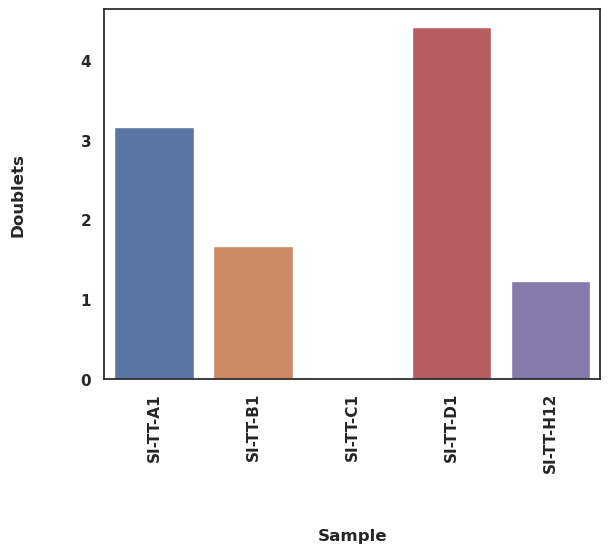

In [55]:
sns.barplot(data=df,x="Sample",y="Doublets",hue="Sample",dodge=False)
plt.xticks(rotation=90)
plt.legend('',frameon=False)


In [56]:
save_dir='/sas/sara/scRNAseq/pendas/'

for key in adatas_dict:

    adatas_dict[key].write_h5ad(save_dir+key+"_original_filtered.h5ad")

In [57]:
save_dir='/sas/sara/scRNAseq/pendas/'


In [58]:
adatas=[]
for x in list(adatas_dict.keys())[1:]:
    adatas.append(adatas_dict[x])
merged=adatas_dict[list(adatas_dict.keys())[0]].concatenate(adatas,join="inner")

In [59]:
merged.write_h5ad(save_dir+"adata.h5ad")

In [60]:
merged = sc.read_h5ad(save_dir+"adata.h5ad")
merged

AnnData object with n_obs × n_vars = 33486 × 16073
    obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection', 'batch'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'rb', 'n_cells-0', 'n_cells_by_counts-0', 'mean_counts-0', 'pct_dropout_by_counts-0', 'total_counts-0', 'log1p_mean_counts-0', 'log1p_total_counts-0', 'n_cells-1', 'n_cells_by_counts-1', 'mean_counts-1', 'pct_dropout_by_counts-1', 'total_counts-1', 'log1p_mean_counts-1', 'log1p_total_counts-1', 'n_cells-2', 'n_cells_by_counts-2', 'mean_counts-2', 'pct_dropout_by_counts-2', 'total_counts-2', 'log1p_mean_counts-2', 'log1p_total_counts-2', 'n_cells-3', 'n_cells_by_counts-3', 'mean_counts-3', 'pct_dropout_by_counts-3', 'total_counts-3', 'lo

In [61]:
## Riken and Gm genes doesn't have gene name
merged = merged[:,~merged.var_names.str.contains("Rik")]
merged = merged[:,~merged.var_names.str.startswith("Gm-")]
merged = merged[:,~merged.var_names.str.startswith("Gm")]

In [62]:
merged.layers["counts"]= merged.X.copy()


/tmp/ipykernel_247376/3181681975.py:1: ImplicitModificationWarning: Setting element `.layers['counts']` of view, initializing view as actual.
  merged.layers["counts"]= merged.X.copy()


In [63]:
sc.pp.highly_variable_genes(merged, flavor="seurat_v3",n_top_genes=10000,layer="counts",subset=False,batch_key="Sample")


In [64]:
high = list(merged.var_names[merged.var["highly_variable"]])
len(high)

10000

In [65]:
merged = merged[:, merged.var_names.isin(high)].copy()
merged

AnnData object with n_obs × n_vars = 33486 × 10000
    obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection', 'batch'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'rb', 'n_cells-0', 'n_cells_by_counts-0', 'mean_counts-0', 'pct_dropout_by_counts-0', 'total_counts-0', 'log1p_mean_counts-0', 'log1p_total_counts-0', 'n_cells-1', 'n_cells_by_counts-1', 'mean_counts-1', 'pct_dropout_by_counts-1', 'total_counts-1', 'log1p_mean_counts-1', 'log1p_total_counts-1', 'n_cells-2', 'n_cells_by_counts-2', 'mean_counts-2', 'pct_dropout_by_counts-2', 'total_counts-2', 'log1p_mean_counts-2', 'log1p_total_counts-2', 'n_cells-3', 'n_cells_by_counts-3', 'mean_counts-3', 'pct_dropout_by_counts-3', 'total_counts-3', 'lo

In [66]:
merged.write_h5ad(save_dir+"adata10000.h5ad")

In [67]:
merged = sc.read_h5ad(save_dir+"adata10000.h5ad")

In [68]:
merged

AnnData object with n_obs × n_vars = 33486 × 10000
    obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection', 'batch'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'rb', 'n_cells-0', 'n_cells_by_counts-0', 'mean_counts-0', 'pct_dropout_by_counts-0', 'total_counts-0', 'log1p_mean_counts-0', 'log1p_total_counts-0', 'n_cells-1', 'n_cells_by_counts-1', 'mean_counts-1', 'pct_dropout_by_counts-1', 'total_counts-1', 'log1p_mean_counts-1', 'log1p_total_counts-1', 'n_cells-2', 'n_cells_by_counts-2', 'mean_counts-2', 'pct_dropout_by_counts-2', 'total_counts-2', 'log1p_mean_counts-2', 'log1p_total_counts-2', 'n_cells-3', 'n_cells_by_counts-3', 'mean_counts-3', 'pct_dropout_by_counts-3', 'total_counts-3', 'lo

In [69]:
#sc.pp.normalize_total(merged, target_sum=1e4)


In [70]:
#sc.pp.log1p(merged)


In [71]:
#sc.tl.pca(merged)

In [72]:
merged.obs["Group"].unique()

['SIX6_D_Cterm', 'WT2', 'WT1', 'H2AX_KI', 'RNF212_KO']
Categories (5, object): ['H2AX_KI', 'RNF212_KO', 'SIX6_D_Cterm', 'WT1', 'WT2']

In [73]:
remap = {'SIX6_D_Cterm':"KI", 
 'WT2': "WT", 
 'WT1':"WT", 
 'H2AX_KI':"KI", 
 'RNF212_KO':"KI"}

In [74]:
merged.obs["Group"] = merged.obs["Group"].astype(str)

In [75]:
merged.obs["Condition"]  = merged.obs["Group"]
merged.obs["Condition"]  = merged.obs["Condition"].map(remap).astype("category")

merged.obs["Condition"] 


ACACGCGCATAGAGGC-1-0    KI
GCCCAGACAGTCGCTG-1-0    KI
TGGGAGACAGTTGGTT-1-0    KI
CACACAACATGGAGAC-1-0    KI
GCCAGGTAGCATGCGA-1-0    KI
                        ..
GAAACCTCACCTGCAG-1-4    KI
CATCCCAAGGAGTATT-1-4    KI
AAGTCGTAGGTGTGAC-1-4    KI
AGTAGTCTCTGGTCAA-1-4    KI
TTCCAATTCACGAACT-1-4    KI
Name: Condition, Length: 33486, dtype: category
Categories (2, object): ['KI', 'WT']

In [76]:
merged.obs["Condition"].unique()

['KI', 'WT']
Categories (2, object): ['KI', 'WT']

In [77]:
#sc.pl.pca(merged,color=["Group","Condition","total_counts","pct_counts_mt","pct_counts_rb","n_genes"])

## Integration ref

In [78]:
ref = sc.read_mtx("/data/scRNAseq/scRNAseq_datasets_v3/spermatogenesis/Files/raw_counts.mtx")
ref = ref.T
ref

AnnData object with n_obs × n_vars = 53510 × 33226

In [79]:
# Cargar genes/variables
var = pd.read_csv("/data/scRNAseq/scRNAseq_datasets_v3/spermatogenesis/Files/genes.tsv",sep="\t")
var



,ID,Symbol
0,ENSMUSG00000102693,4933401J01Rik
1,ENSMUSG00000051951,Xkr4
2,ENSMUSG00000103377,Gm37180
3,ENSMUSG00000104017,Gm37363
4,ENSMUSG00000103025,Gm37686
...,...,...
33221,ENSG00000281637,Metazoa_SRP
33222,ENSG00000160305,DIP2A
33223,ENSG00000223692,DIP2A-IT1
33224,ENSG00000160307,S100B


In [80]:
obs = pd.read_csv("/data/scRNAseq/scRNAseq_datasets_v3/spermatogenesis/Files/cell_metadata.txt", sep=" ")
obs

,Sample,Barcode,Library,is_cell_control,total_features_by_counts,log10_total_features_by_counts,total_counts,log10_total_counts,pct_counts_in_top_50_features,pct_counts_in_top_100_features,pct_counts_in_top_200_features,pct_counts_in_top_500_features,BroadClusters,AnnotatedClusters
1,B6,AAACCTGAGATGGCGT-1,do17815,False,4761,3.677789,41018,4.612985,26.059291,34.158174,45.167975,63.937783,Germ,S9
2,B6,AAACCTGAGTTCGATC-1,do17815,False,3211,3.506776,20236,4.306146,30.460565,39.528563,51.373789,70.473414,Germ,S10
3,B6,AAACCTGTCAAGATCC-1,do17815,False,6175,3.790707,41335,4.616328,12.710778,19.644369,29.302044,46.931172,Germ,S3
4,B6,AAACCTGTCACGATGT-1,do17815,False,4873,3.687886,13920,4.143670,13.067529,20.395115,29.676724,45.416667,Germ,Spermatogonia
5,B6,AAACCTGTCTGCTGCT-1,do17815,False,6029,3.780317,48207,4.683119,14.773788,21.768623,31.586699,50.326716,Germ,S6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53506,P35,TTTGTCACACCATGTA-1,do17827,False,5041,3.702603,29586,4.471101,16.882990,25.113230,36.013660,54.498750,Germ,S1
53507,P35,TTTGTCACATTCCTGC-1,do17827,False,6641,3.822299,56798,4.754341,16.366770,24.176910,34.157890,51.320470,Germ,lP2
53508,P35,TTTGTCAGTCCGAAGA-1,do17827,False,7140,3.853759,83591,4.922165,16.361810,24.631840,35.058800,52.728160,Germ,D
53509,P35,TTTGTCAGTGCGAAAC-1,do17827,False,5774,3.761552,40404,4.606435,13.256110,20.468270,30.944960,49.680720,Germ,S4


In [81]:
ref.obs = obs
ref.var = var
ref

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/anndata/_core/anndata.py:850: UserWarning: 
AnnData expects .obs.index to contain strings, but got values like:
    [1, 2, 3, 4, 5]

    Inferred to be: integer

  value_idx = self._prep_dim_index(value.index, attr)


AnnData object with n_obs × n_vars = 53510 × 33226
    obs: 'Sample', 'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts', 'log10_total_features_by_counts', 'total_counts', 'log10_total_counts', 'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features', 'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features', 'BroadClusters', 'AnnotatedClusters'
    var: 'ID', 'Symbol'

In [82]:
ref.obs["type_data"]="Ref"

In [83]:
ref.obs.index = ref.obs["Barcode"]+"_"+ref.obs["Sample"]
ref.obs

,Sample,Barcode,Library,is_cell_control,total_features_by_counts,log10_total_features_by_counts,total_counts,log10_total_counts,pct_counts_in_top_50_features,pct_counts_in_top_100_features,pct_counts_in_top_200_features,pct_counts_in_top_500_features,BroadClusters,AnnotatedClusters,type_data
AAACCTGAGATGGCGT-1_B6,B6,AAACCTGAGATGGCGT-1,do17815,False,4761,3.677789,41018,4.612985,26.059291,34.158174,45.167975,63.937783,Germ,S9,Ref
AAACCTGAGTTCGATC-1_B6,B6,AAACCTGAGTTCGATC-1,do17815,False,3211,3.506776,20236,4.306146,30.460565,39.528563,51.373789,70.473414,Germ,S10,Ref
AAACCTGTCAAGATCC-1_B6,B6,AAACCTGTCAAGATCC-1,do17815,False,6175,3.790707,41335,4.616328,12.710778,19.644369,29.302044,46.931172,Germ,S3,Ref
AAACCTGTCACGATGT-1_B6,B6,AAACCTGTCACGATGT-1,do17815,False,4873,3.687886,13920,4.143670,13.067529,20.395115,29.676724,45.416667,Germ,Spermatogonia,Ref
AAACCTGTCTGCTGCT-1_B6,B6,AAACCTGTCTGCTGCT-1,do17815,False,6029,3.780317,48207,4.683119,14.773788,21.768623,31.586699,50.326716,Germ,S6,Ref
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTCACACCATGTA-1_P35,P35,TTTGTCACACCATGTA-1,do17827,False,5041,3.702603,29586,4.471101,16.882990,25.113230,36.013660,54.498750,Germ,S1,Ref
TTTGTCACATTCCTGC-1_P35,P35,TTTGTCACATTCCTGC-1,do17827,False,6641,3.822299,56798,4.754341,16.366770,24.176910,34.157890,51.320470,Germ,lP2,Ref
TTTGTCAGTCCGAAGA-1_P35,P35,TTTGTCAGTCCGAAGA-1,do17827,False,7140,3.853759,83591,4.922165,16.361810,24.631840,35.058800,52.728160,Germ,D,Ref
TTTGTCAGTGCGAAAC-1_P35,P35,TTTGTCAGTGCGAAAC-1,do17827,False,5774,3.761552,40404,4.606435,13.256110,20.468270,30.944960,49.680720,Germ,S4,Ref


In [84]:
ref.obs["Sample"].unique()

array(['B6', 'Tc0', 'Tc1', 'P5', 'P10', 'P15', 'P20', 'P25', 'P30', 'P35'],
      dtype=object)

In [85]:
ref = ref[ref.obs["Sample"].isin(["P35","B6"])]
ref

View of AnnData object with n_obs × n_vars = 6515 × 33226
    obs: 'Sample', 'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts', 'log10_total_features_by_counts', 'total_counts', 'log10_total_counts', 'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features', 'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features', 'BroadClusters', 'AnnotatedClusters', 'type_data'
    var: 'ID', 'Symbol'

In [86]:
ref.var.index = ref.var["Symbol"]



In [87]:
list(ref.obs["AnnotatedClusters"].unique())

['S9',
 'S10',
 'S3',
 'Spermatogonia',
 'S6',
 'S7',
 'eP1',
 'S11',
 'mP',
 'Sertoli',
 'eP2',
 'S5',
 'MI',
 'S8',
 'lP2',
 'S4',
 'S2',
 'lP1',
 'Outliers',
 'S1',
 'MII',
 'D',
 'Leydig_1',
 'Endothelial_cells']

In [88]:
counts = pd.DataFrame.sparse.from_spmatrix(ref.X) ## Check is raw counts
counts

,0,1,2,3,4,5,6,7,8,9,...,33216,33217,33218,33219,33220,33221,33222,33223,33224,33225
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6510,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6511,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6512,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6513,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [89]:
pd.DataFrame.sparse.from_spmatrix(merged.X)

,0,1,2,3,4,5,6,7,8,9,...,9990,9991,9992,9993,9994,9995,9996,9997,9998,9999
0,0,0,0,5,45,0,0,1,0,0,...,2,60,13,0,43,0,1,0,0,11
1,0,0,0,1,33,0,0,2,0,0,...,2,70,10,0,126,0,2,0,0,11
2,0,2,0,2,36,0,0,1,0,0,...,5,47,6,0,50,0,0,0,0,4
3,0,0,1,3,41,0,0,3,0,0,...,3,116,14,2,145,0,1,0,0,25
4,0,0,0,4,22,0,0,3,0,0,...,2,29,7,0,52,0,1,0,0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33481,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
33482,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
33483,0,0,0,0,0,0,0,0,0,0,...,0,2,0,0,0,0,0,0,0,0
33484,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0


In [90]:
merged.var_names.equals(ref.var_names)


False

In [91]:
common_genes = merged.var_names.intersection(ref.var_names)
common_genes

Index(['Rp1', 'Sox17', 'Tcea1', 'Atp6v1h', 'Rb1cc1', 'Pcmtd1', 'Sntg1', 'Rrs1',
       'Adhfe1', 'Mybl1',
       ...
       'mt-Co3', 'mt-Nd3', 'mt-Nd4l', 'mt-Nd4', 'mt-Nd5', 'mt-Nd6', 'mt-Cytb',
       'AC168977.1', 'AC132444.6', 'Vamp7'],
      dtype='object', length=9531)

In [92]:
print(merged.var_names.is_unique)  # debería ser True
print(ref.var_names.is_unique)     # debería ser True

True
False


In [93]:
ref.var_names_make_unique()
merged.var_names_make_unique()



/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/anndata/_core/anndata.py:1897: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/anndata/_core/anndata.py:1899: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [94]:
merged_sub = merged[:, common_genes]
ref_sub = ref[:, common_genes]

In [95]:
merged_sub.obs["type_data"]="Query"

merged_ref = merged_sub.concatenate(ref_sub)
merged_ref

/tmp/ipykernel_247376/964037343.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  merged_sub.obs["type_data"]="Query"
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/anndata/_core/anndata.py:1897: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/anndata/_core/anndata.py:1897: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/anndata/_core/anndata.py:1897: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 40001 × 9531
    obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection', 'batch', 'Condition', 'type_data', 'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts', 'log10_total_features_by_counts', 'log10_total_counts', 'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features', 'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features', 'BroadClusters', 'AnnotatedClusters'
    var: 'gene_ids-0', 'feature_types-0', 'genome-0', 'mt-0', 'rb-0', 'n_cells-0-0', 'n_cells_by_counts-0-0', 'mean_counts-0-0', 'pct_dropout_by_counts-0-0', 'total_counts-0-0', 'log1p_mean_counts-0-0', 'log1p_total_counts-0-0', 'n_cells-1-0', 'n_cells_by_counts-1-0', 'mea

In [96]:
merged_ref.obs

,Sample,Group,n_genes,n_counts,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_rb,pct_counts_rb,...,is_cell_control,total_features_by_counts,log10_total_features_by_counts,log10_total_counts,pct_counts_in_top_50_features,pct_counts_in_top_100_features,pct_counts_in_top_200_features,pct_counts_in_top_500_features,BroadClusters,AnnotatedClusters
ACACGCGCATAGAGGC-1-0-0,SI-TT-A1,SIX6_D_Cterm,7075.0,88695.0,7064.0,88695,1746.0,1.968544,6467.0,7.291279,...,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GCCCAGACAGTCGCTG-1-0-0,SI-TT-A1,SIX6_D_Cterm,7120.0,73231.0,7111.0,73231,1639.0,2.238123,6126.0,8.365310,...,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TGGGAGACAGTTGGTT-1-0-0,SI-TT-A1,SIX6_D_Cterm,6812.0,70090.0,6807.0,70090,1430.0,2.040234,5066.0,7.227850,...,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CACACAACATGGAGAC-1-0-0,SI-TT-A1,SIX6_D_Cterm,6892.0,68932.0,6885.0,68932,2420.0,3.510706,6916.0,10.033076,...,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GCCAGGTAGCATGCGA-1-0-0,SI-TT-A1,SIX6_D_Cterm,6387.0,58809.0,6382.0,58809,1162.0,1.975888,5279.0,8.976517,...,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTCACACCATGTA-1_P35-1,P35,NaN,NaN,NaN,NaN,29586,NaN,NaN,NaN,NaN,...,False,5041.0,3.702603,4.471101,16.88299,25.11323,36.01366,54.49875,Germ,S1
TTTGTCACATTCCTGC-1_P35-1,P35,NaN,NaN,NaN,NaN,56798,NaN,NaN,NaN,NaN,...,False,6641.0,3.822299,4.754341,16.36677,24.17691,34.15789,51.32047,Germ,lP2
TTTGTCAGTCCGAAGA-1_P35-1,P35,NaN,NaN,NaN,NaN,83591,NaN,NaN,NaN,NaN,...,False,7140.0,3.853759,4.922165,16.36181,24.63184,35.05880,52.72816,Germ,D
TTTGTCAGTGCGAAAC-1_P35-1,P35,NaN,NaN,NaN,NaN,40404,NaN,NaN,NaN,NaN,...,False,5774.0,3.761552,4.606435,13.25611,20.46827,30.94496,49.68072,Germ,S4


In [97]:
merged_ref.obs["AnnotatedClusters"] = merged_ref.obs["AnnotatedClusters"].fillna("Unknown")
merged_ref.obs


,Sample,Group,n_genes,n_counts,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_rb,pct_counts_rb,...,is_cell_control,total_features_by_counts,log10_total_features_by_counts,log10_total_counts,pct_counts_in_top_50_features,pct_counts_in_top_100_features,pct_counts_in_top_200_features,pct_counts_in_top_500_features,BroadClusters,AnnotatedClusters
ACACGCGCATAGAGGC-1-0-0,SI-TT-A1,SIX6_D_Cterm,7075.0,88695.0,7064.0,88695,1746.0,1.968544,6467.0,7.291279,...,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Unknown
GCCCAGACAGTCGCTG-1-0-0,SI-TT-A1,SIX6_D_Cterm,7120.0,73231.0,7111.0,73231,1639.0,2.238123,6126.0,8.365310,...,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Unknown
TGGGAGACAGTTGGTT-1-0-0,SI-TT-A1,SIX6_D_Cterm,6812.0,70090.0,6807.0,70090,1430.0,2.040234,5066.0,7.227850,...,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Unknown
CACACAACATGGAGAC-1-0-0,SI-TT-A1,SIX6_D_Cterm,6892.0,68932.0,6885.0,68932,2420.0,3.510706,6916.0,10.033076,...,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Unknown
GCCAGGTAGCATGCGA-1-0-0,SI-TT-A1,SIX6_D_Cterm,6387.0,58809.0,6382.0,58809,1162.0,1.975888,5279.0,8.976517,...,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Unknown
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTCACACCATGTA-1_P35-1,P35,NaN,NaN,NaN,NaN,29586,NaN,NaN,NaN,NaN,...,False,5041.0,3.702603,4.471101,16.88299,25.11323,36.01366,54.49875,Germ,S1
TTTGTCACATTCCTGC-1_P35-1,P35,NaN,NaN,NaN,NaN,56798,NaN,NaN,NaN,NaN,...,False,6641.0,3.822299,4.754341,16.36677,24.17691,34.15789,51.32047,Germ,lP2
TTTGTCAGTCCGAAGA-1_P35-1,P35,NaN,NaN,NaN,NaN,83591,NaN,NaN,NaN,NaN,...,False,7140.0,3.853759,4.922165,16.36181,24.63184,35.05880,52.72816,Germ,D
TTTGTCAGTGCGAAAC-1_P35-1,P35,NaN,NaN,NaN,NaN,40404,NaN,NaN,NaN,NaN,...,False,5774.0,3.761552,4.606435,13.25611,20.46827,30.94496,49.68072,Germ,S4


In [98]:
merged_ref.layers["counts"]= merged_ref.X.copy()

In [99]:
merged_ref.obs["type_data"]

ACACGCGCATAGAGGC-1-0-0      Query
GCCCAGACAGTCGCTG-1-0-0      Query
TGGGAGACAGTTGGTT-1-0-0      Query
CACACAACATGGAGAC-1-0-0      Query
GCCAGGTAGCATGCGA-1-0-0      Query
                            ...  
TTTGTCACACCATGTA-1_P35-1      Ref
TTTGTCACATTCCTGC-1_P35-1      Ref
TTTGTCAGTCCGAAGA-1_P35-1      Ref
TTTGTCAGTGCGAAAC-1_P35-1      Ref
TTTGTCATCATCATTC-1_P35-1      Ref
Name: type_data, Length: 40001, dtype: object

In [100]:
scvi.model.SCVI.setup_anndata(merged_ref,layer="counts",batch_key="Sample",labels_key="AnnotatedClusters",categorical_covariate_keys=["type_data"])


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


In [101]:
merged_ref.layers["counts"]

<40001x9531 sparse matrix of type '<class 'numpy.float64'>'
	with 56342309 stored elements in Compressed Sparse Row format>

In [102]:

vae = scvi.model.SCVI(
    merged_ref,
    n_layers=2,
    n_latent=30
)
vae.train()
vae.save(save_dir+'/model_batch_gene_zinb_2layer_latent30_ref',overwrite = True)

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/lightning/fabric/plugins/environments/slurm.py:165: PossibleUserWarning: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/sara/.local/lib/python3.11/site-packages/ipyke ...
  rank_zero_warn(
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/lightning/fabric/plugins/environments/slurm.py:165: PossibleUserWarning: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/sara/.local/lib/python3.11/site-packages/ipyke ...
  rank_zero_warn(
You are using a CUDA device ('NVIDIA A40') that has Tens

Epoch 200/200: 100%|██████████| 200/200 [13:43<00:00,  4.04s/it, v_num=1, train_loss_step=3.93e+3, train_loss_epoch=3.58e+3]

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [13:43<00:00,  4.12s/it, v_num=1, train_loss_step=3.93e+3, train_loss_epoch=3.58e+3]


In [103]:
lvae = scvi.model.SCANVI.from_scvi_model(
    vae,
    adata=merged_ref,
    unlabeled_category="Unknown",
    labels_key="AnnotatedClusters",
    )

In [104]:
lvae.train(max_epochs=20, n_samples_per_label=100)
lvae.save(save_dir +"/lvae_scanvi_transfer_ref", overwrite = True)


INFO     Training for 20 epochs.                                                                                   


/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/lightning/fabric/plugins/environments/slurm.py:165: PossibleUserWarning: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/sara/.local/lib/python3.11/site-packages/ipyke ...
  rank_zero_warn(
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/lightning/fabric/plugins/environments/slurm.py:165: PossibleUserWarning: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/sara/.local/lib/python3.11/site-packages/ipyke ...
  rank_zero_warn(
You are using a CUDA device ('NVIDIA A40') that has Tens

Epoch 20/20: 100%|██████████| 20/20 [02:48<00:00,  8.46s/it, v_num=1, train_loss_step=3.04e+3, train_loss_epoch=3.65e+3]

`Trainer.fit` stopped: `max_epochs=20` reached.


Epoch 20/20: 100%|██████████| 20/20 [02:48<00:00,  8.40s/it, v_num=1, train_loss_step=3.04e+3, train_loss_epoch=3.65e+3]


In [105]:
merged_ref.obs["celltype_scanvi"] = merged_ref.obs["AnnotatedClusters"]
merged_ref.obs["celltype_scanvi"] = lvae.predict(merged_ref)


In [106]:
merged_ref.obs.to_csv(save_dir+"/prediction_spermato.csv")

In [107]:
merged_ref.obs

,Sample,Group,n_genes,n_counts,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_rb,pct_counts_rb,...,log10_total_counts,pct_counts_in_top_50_features,pct_counts_in_top_100_features,pct_counts_in_top_200_features,pct_counts_in_top_500_features,BroadClusters,AnnotatedClusters,_scvi_batch,_scvi_labels,celltype_scanvi
ACACGCGCATAGAGGC-1-0-0,SI-TT-A1,SIX6_D_Cterm,7075.0,88695.0,7064.0,88695,1746.0,1.968544,6467.0,7.291279,...,NaN,NaN,NaN,NaN,NaN,NaN,Unknown,2,24,MI
GCCCAGACAGTCGCTG-1-0-0,SI-TT-A1,SIX6_D_Cterm,7120.0,73231.0,7111.0,73231,1639.0,2.238123,6126.0,8.365310,...,NaN,NaN,NaN,NaN,NaN,NaN,Unknown,2,24,D
TGGGAGACAGTTGGTT-1-0-0,SI-TT-A1,SIX6_D_Cterm,6812.0,70090.0,6807.0,70090,1430.0,2.040234,5066.0,7.227850,...,NaN,NaN,NaN,NaN,NaN,NaN,Unknown,2,24,MI
CACACAACATGGAGAC-1-0-0,SI-TT-A1,SIX6_D_Cterm,6892.0,68932.0,6885.0,68932,2420.0,3.510706,6916.0,10.033076,...,NaN,NaN,NaN,NaN,NaN,NaN,Unknown,2,24,lP2
GCCAGGTAGCATGCGA-1-0-0,SI-TT-A1,SIX6_D_Cterm,6387.0,58809.0,6382.0,58809,1162.0,1.975888,5279.0,8.976517,...,NaN,NaN,NaN,NaN,NaN,NaN,Unknown,2,24,D
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTCACACCATGTA-1_P35-1,P35,NaN,NaN,NaN,NaN,29586,NaN,NaN,NaN,NaN,...,4.471101,16.88299,25.11323,36.01366,54.49875,Germ,S1,1,6,S1
TTTGTCACATTCCTGC-1_P35-1,P35,NaN,NaN,NaN,NaN,56798,NaN,NaN,NaN,NaN,...,4.754341,16.36677,24.17691,34.15789,51.32047,Germ,lP2,1,23,lP2
TTTGTCAGTCCGAAGA-1_P35-1,P35,NaN,NaN,NaN,NaN,83591,NaN,NaN,NaN,NaN,...,4.922165,16.36181,24.63184,35.05880,52.72816,Germ,D,1,0,D
TTTGTCAGTGCGAAAC-1_P35-1,P35,NaN,NaN,NaN,NaN,40404,NaN,NaN,NaN,NaN,...,4.606435,13.25611,20.46827,30.94496,49.68072,Germ,S4,1,11,S4


In [108]:
merged_ref.obs["celltype_scanvi"] = merged_ref.obs["celltype_scanvi"].astype("category")
Ref = merged_ref[(merged_ref.obs["type_data"]=="Ref")]
df = Ref.obs.groupby(["AnnotatedClusters","celltype_scanvi"]).size().unstack(fill_value=0)
df

celltype_scanvi,D,Leydig_1,MI,MII,Outliers,S1,S10,S11,S2,S3,...,S7,S8,S9,Sertoli,Spermatogonia,eP1,eP2,lP1,lP2,mP
AnnotatedClusters,,,,,,,,,,,,,,,,,,,,,
D,215,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Endothelial_cells,0,4,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Leydig_1,0,15,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
MI,5,0,133,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
MII,0,0,23,192,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Outliers,5,0,9,2,246,1,0,0,5,2,...,0,0,0,3,0,0,0,1,8,3
S1,0,0,0,7,0,452,0,0,36,0,...,0,0,0,0,0,0,0,0,0,0
S10,0,0,0,0,0,0,741,0,0,0,...,0,0,4,0,0,0,0,0,0,0
S11,0,0,0,0,1,0,189,665,0,0,...,0,0,0,0,0,0,0,0,0,0


Text(0.5, 1.0, 'Confusion matrix')

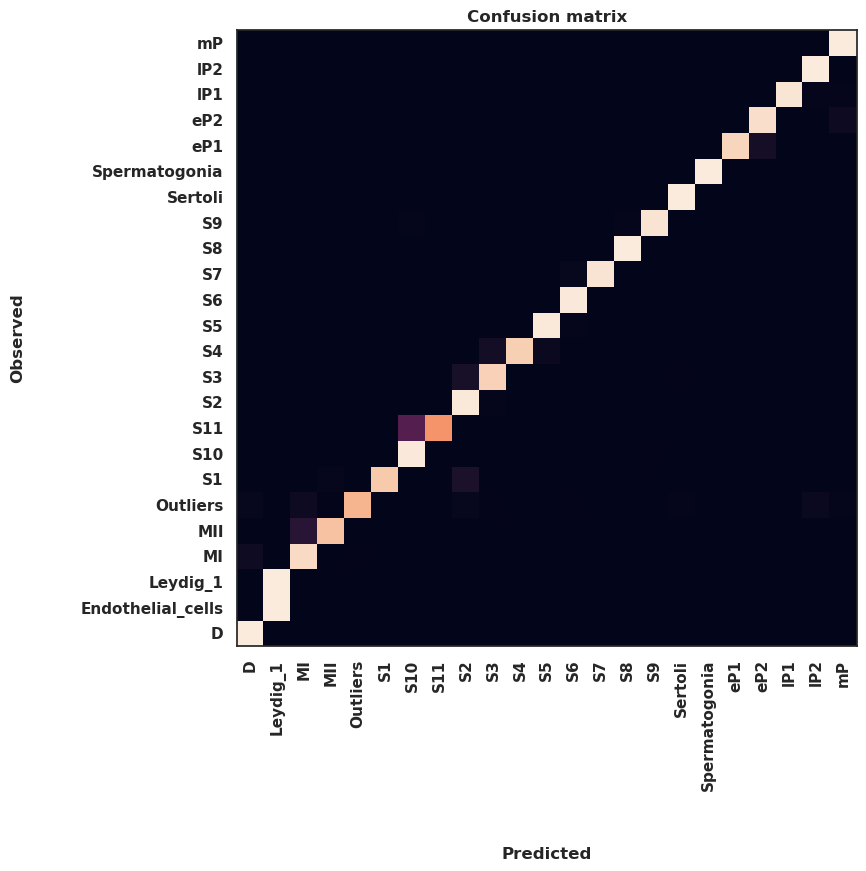

In [109]:
conf_mat = df / df.sum(axis=1).values[:, np.newaxis]
plt.figure(figsize=(8, 8))
_ = plt.pcolor(conf_mat)
_ = plt.xticks(np.arange(0.5, len(df.columns), 1), df.columns, rotation=90)
_ = plt.yticks(np.arange(0.5, len(df.index), 1), df.index)
plt.xlabel("Predicted")
plt.ylabel("Observed")
plt.title("Confusion matrix")

In [110]:
vae

SCVI Model with the following params: 
n_hidden: 128, n_latent: 30, n_layers: 2, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb, 
latent_distribution: normal
Training status: Trained
Model's adata is minified?: False

In [111]:
latent = vae.get_latent_representation()
merged_ref.obsm["X_scVI"] = latent

In [112]:
sc.pp.neighbors(merged_ref, use_rep="X_scVI",key_added="neighbors_model")
sc.tl.umap(merged_ref, min_dist=0.2,neighbors_key="neighbors_model")

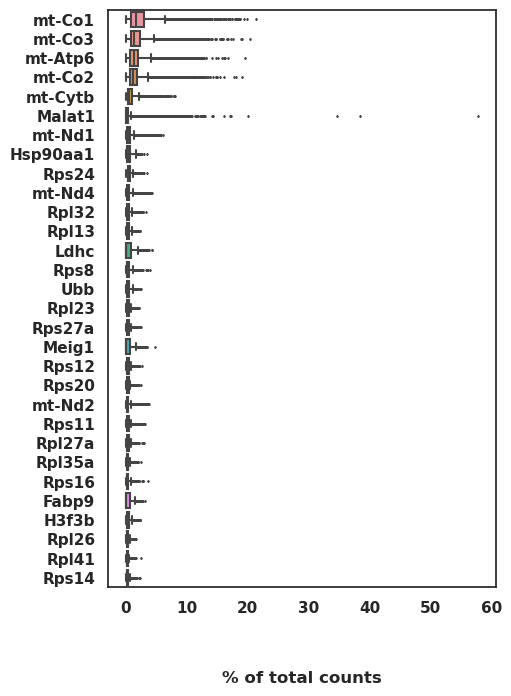

In [113]:
sc.pl.highest_expr_genes(adata, n_top=30)

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


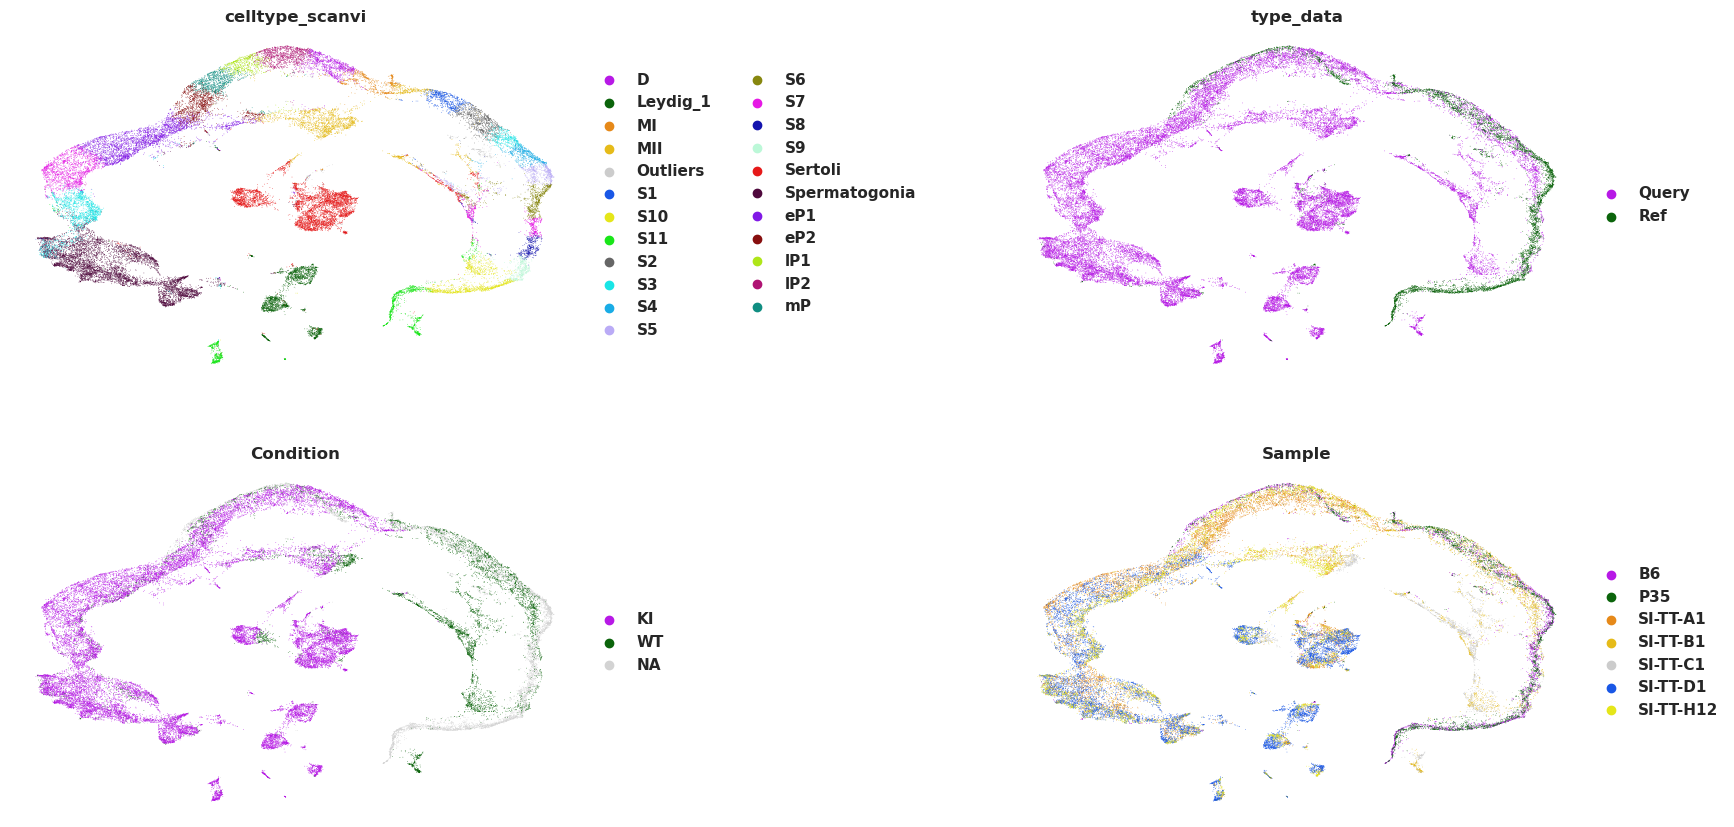

In [114]:
sc.pl.umap(
    merged_ref,
    color=["celltype_scanvi","type_data","Condition","Sample"],
    ncols=2,
    frameon=False,
    facecolor=None,
    palette=categorical_palette2,
    neighbors_key="neighbors_model",
    size=1,
    #title="Integration UMAP Lymph node all features",
    wspace=0.6
)

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


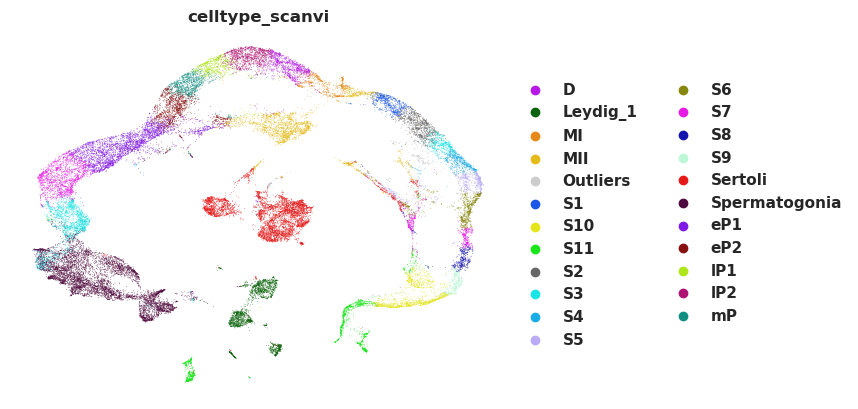

In [115]:
sc.pl.umap(
    merged_ref,
    color=["celltype_scanvi"],
    ncols=2,
    frameon=False,
    facecolor=None,
    palette=categorical_palette2,
    neighbors_key="neighbors_model",
    size=1,
    #title="Integration UMAP Lymph node all features",
    wspace=0.6
)


In [116]:
adata = merged_ref[merged_ref.obs["type_data"]=="Query"]
adata

View of AnnData object with n_obs × n_vars = 33486 × 9531
    obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection', 'batch', 'Condition', 'type_data', 'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts', 'log10_total_features_by_counts', 'log10_total_counts', 'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features', 'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features', 'BroadClusters', 'AnnotatedClusters', '_scvi_batch', '_scvi_labels', 'celltype_scanvi'
    var: 'gene_ids-0', 'feature_types-0', 'genome-0', 'mt-0', 'rb-0', 'n_cells-0-0', 'n_cells_by_counts-0-0', 'mean_counts-0-0', 'pct_dropout_by_counts-0-0', 'total_counts-0-0', 'log1p_mean_counts-0-0', 'log1p_total

In [117]:
adata = adata.copy()

In [118]:
scvi.model.SCVI.setup_anndata(adata,layer="counts",batch_key="Sample",categorical_covariate_keys=["Condition"])


In [119]:

vae = scvi.model.SCVI(
    adata,
    n_layers=2,
    n_latent=30
)
vae.train()
vae.save(save_dir+'/model_batch_gene_zinb_2layer_latent30_adata8',overwrite = True)

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/lightning/fabric/plugins/environments/slurm.py:165: PossibleUserWarning: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/sara/.local/lib/python3.11/site-packages/ipyke ...
  rank_zero_warn(
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/lightning/fabric/plugins/environments/slurm.py:165: PossibleUserWarning: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/sara/.local/lib/python3.11/site-packages/ipyke ...
  rank_zero_warn(
You are using a CUDA device ('NVIDIA A40') that has Tens

Epoch 239/239: 100%|██████████| 239/239 [13:56<00:00,  3.43s/it, v_num=1, train_loss_step=3.03e+3, train_loss_epoch=3.01e+3]

`Trainer.fit` stopped: `max_epochs=239` reached.


Epoch 239/239: 100%|██████████| 239/239 [13:56<00:00,  3.50s/it, v_num=1, train_loss_step=3.03e+3, train_loss_epoch=3.01e+3]


In [120]:
latent = vae.get_latent_representation()
adata.obsm["X_scVI"] = latent

In [121]:
sc.pp.neighbors(adata, use_rep="X_scVI",key_added="neighbors_model")
sc.tl.umap(adata, min_dist=0.2,neighbors_key="neighbors_model")

In [122]:
adata.obs.columns

Index(['Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts',
       'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb',
       'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts',
       'pct_counts_in_top_20_genes', 'log1p_total_counts_mt',
       'log1p_total_counts_rb', 'doublet', 'doublet_score',
       'doublet_doubletdetection', 'batch', 'Condition', 'type_data',
       'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts',
       'log10_total_features_by_counts', 'log10_total_counts',
       'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features',
       'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features',
       'BroadClusters', 'AnnotatedClusters', '_scvi_batch', '_scvi_labels',
       'celltype_scanvi'],
      dtype='object')

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


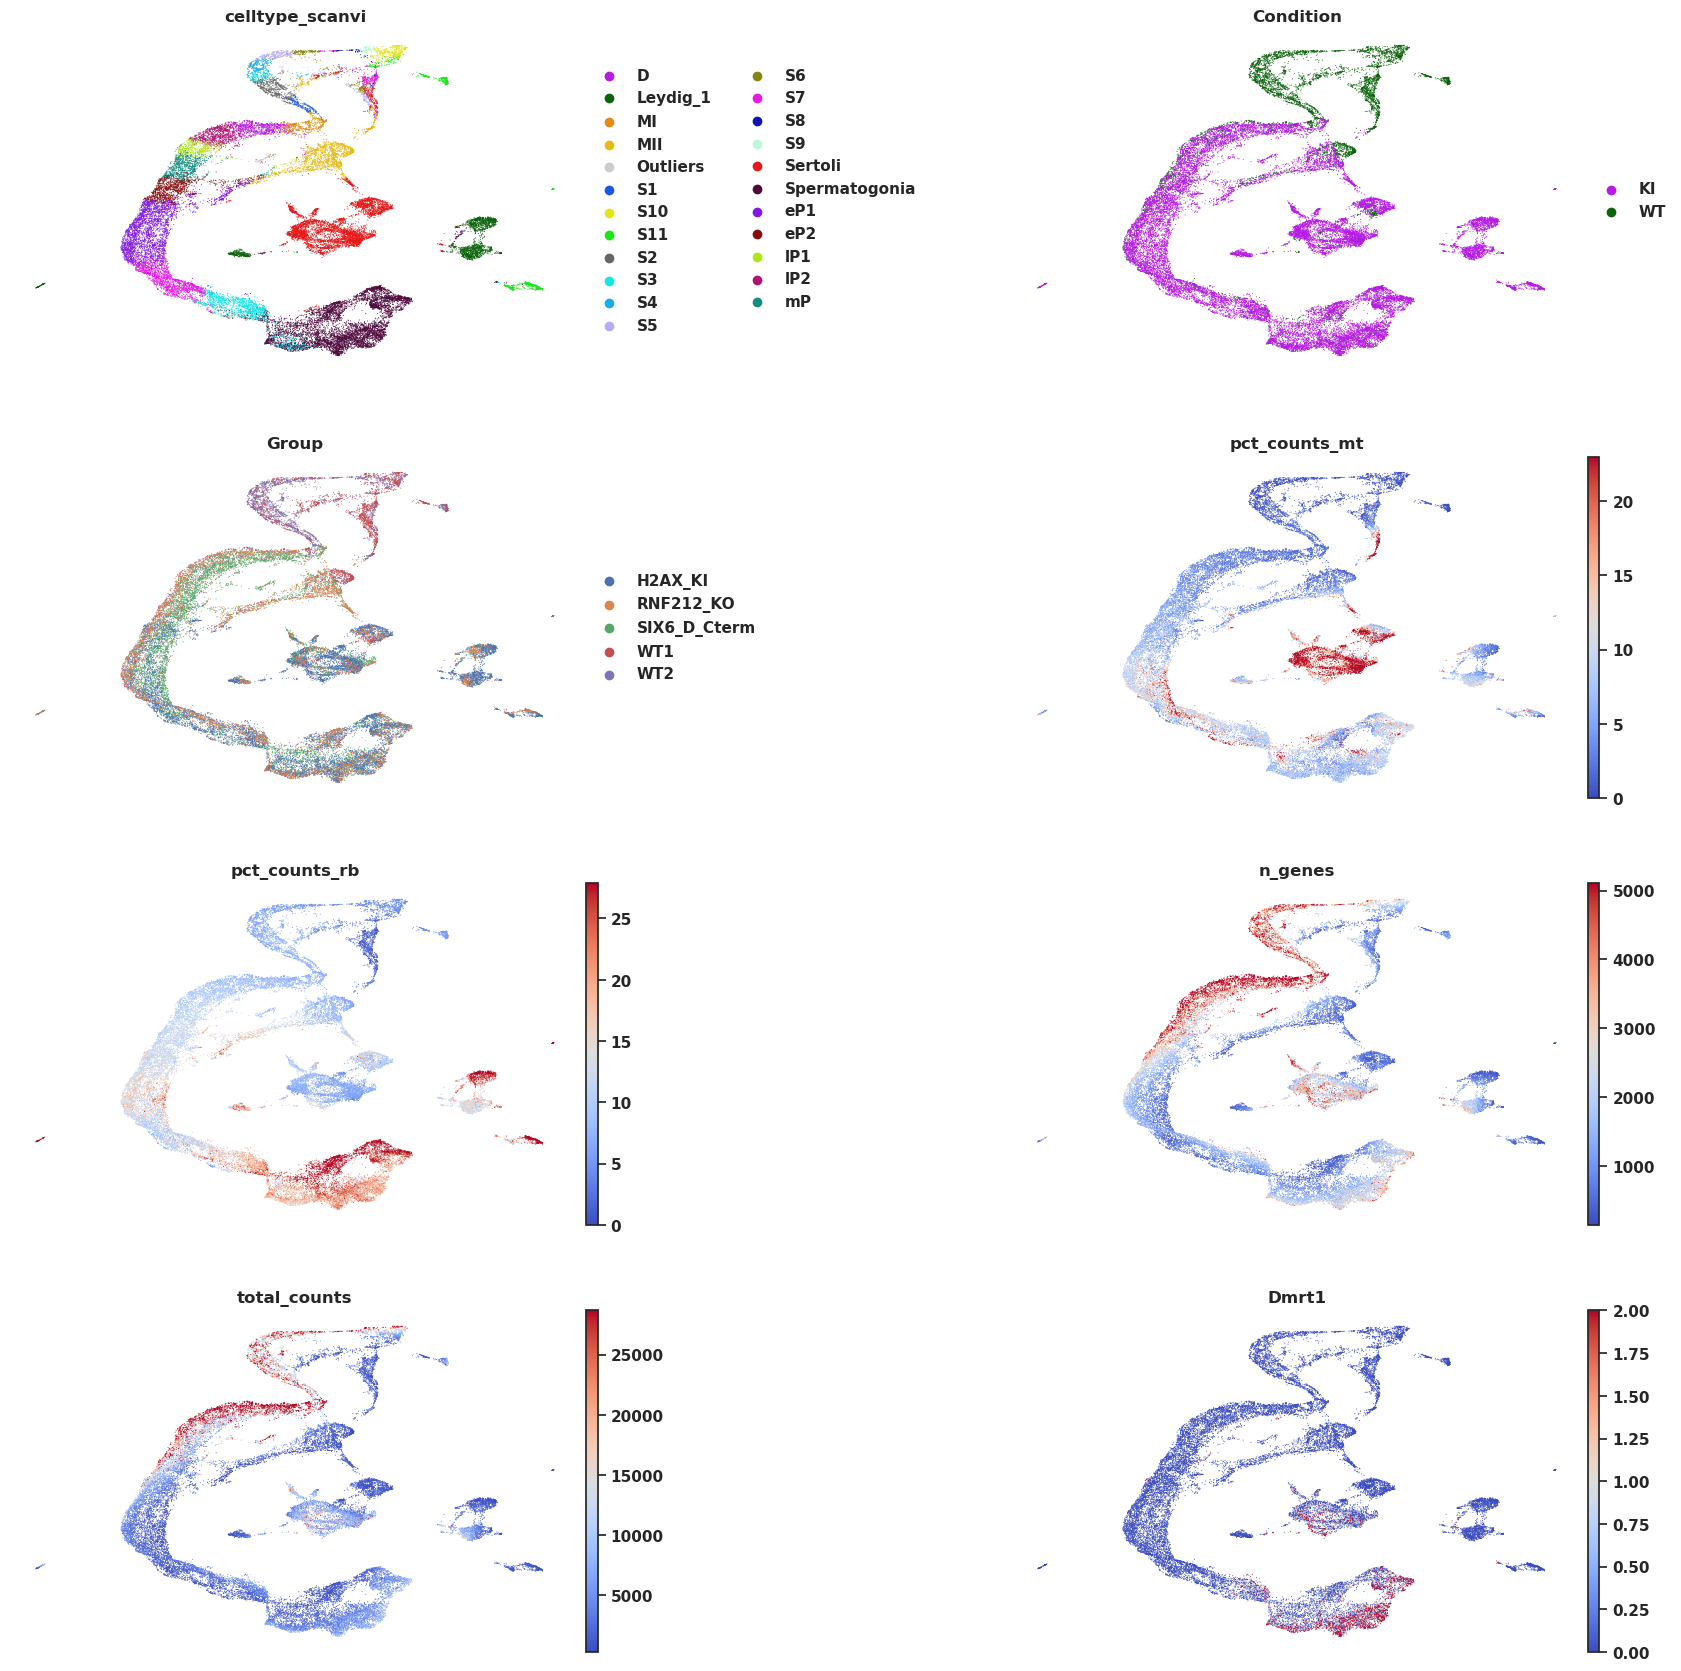

In [123]:
sc.pl.umap(
    adata,
    color=["celltype_scanvi","Condition","Group","pct_counts_mt","pct_counts_rb","n_genes","total_counts","Dmrt1"],
    ncols=2,
    frameon=False,
    facecolor=None,
    vmax="p95",
    cmap="coolwarm",
    neighbors_key="neighbors_model",
    size=2,
    #title="Integration UMAP Lymph node all features",
    wspace=0.6
)

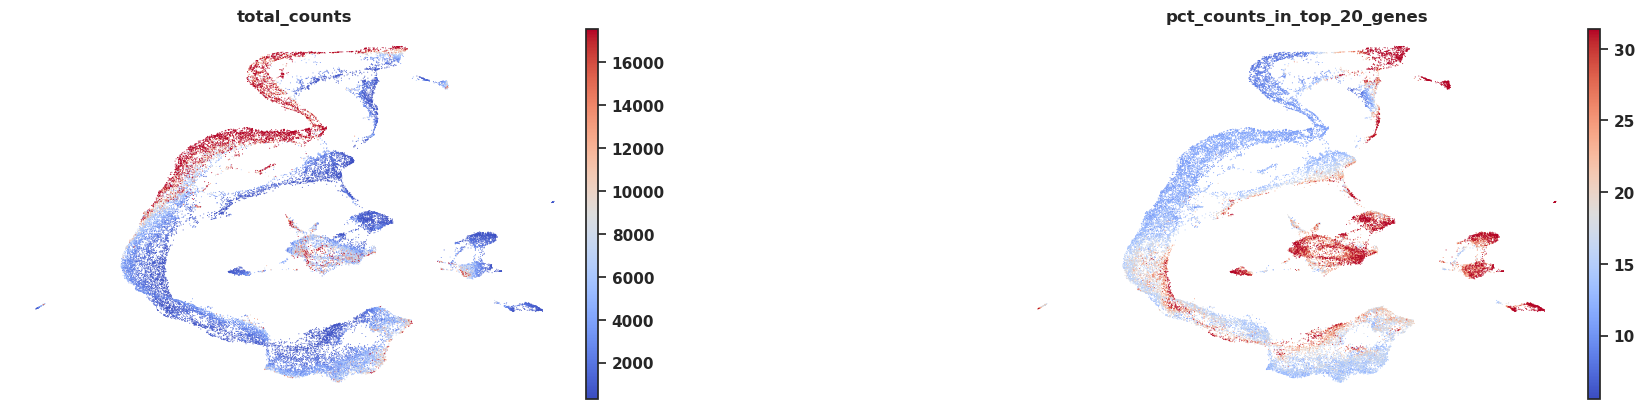

In [124]:
sc.pl.umap(
    adata,
    color=["total_counts","pct_counts_in_top_20_genes"],
    ncols=2,
    frameon=False,
    facecolor=None,
    vmax="p90",
    cmap="coolwarm",
    neighbors_key="neighbors_model",
    size=2,
    #title="Integration UMAP Lymph node all features",
    wspace=0.6
)

In [125]:
adata.write_h5ad(save_dir+"/manually_annotated_adata_label8.h5ad")

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


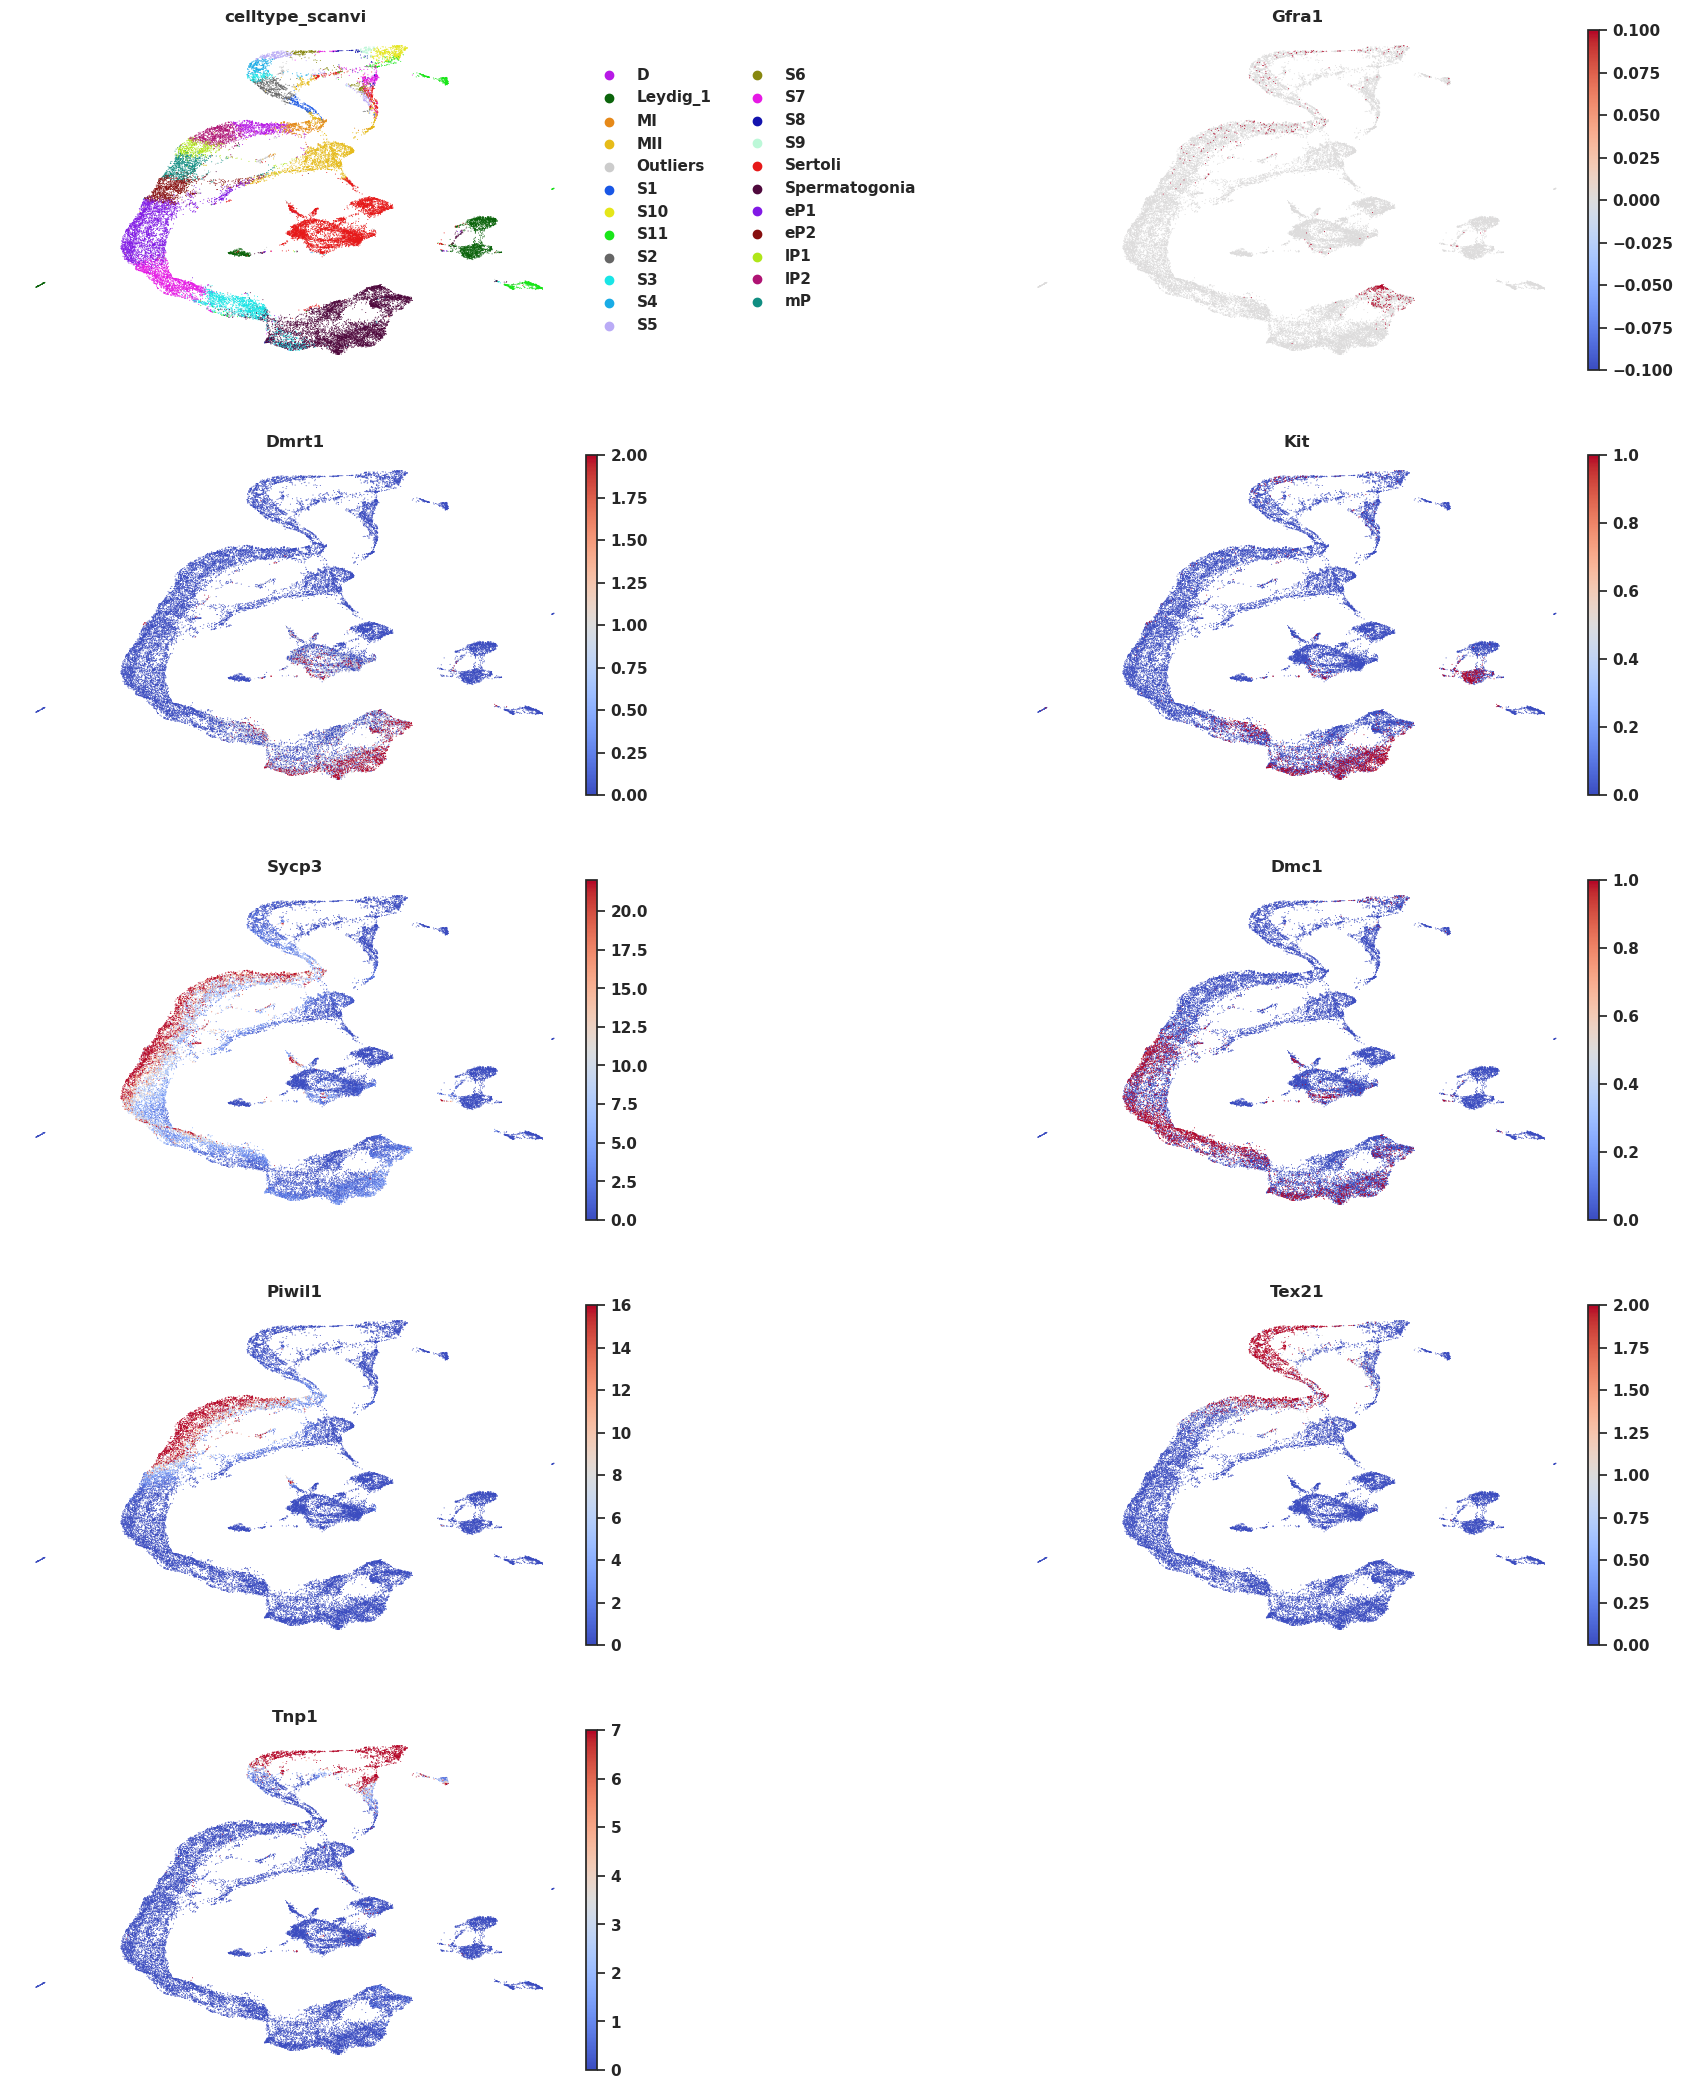

In [126]:
sc.pl.umap(
    adata,
    color=["celltype_scanvi","Gfra1","Dmrt1","Kit","Sycp3","Dmc1","Piwil1","Tex21","Tnp1"],
    ncols=2,
    frameon=False,
    facecolor=None,
    vmax="p95",
    cmap="coolwarm",
    neighbors_key="neighbors_model",
    size=2,
    #title="Integration UMAP Lymph node all features",
    wspace=0.6
)